# M03 · Probabilités conditionnelles — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m03_probabilites_conditionnelles/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M03.1 à M03.11, M03.14, M03.15 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M03.19 | Jointe, marginales et conditionnelles à partir d'un tableau de comptages · `joint_from_counts, marginal, conditional` | 🔨 | ★ | 20 |
|  | M03.20 | Tester l'indépendance avec une tolérance · `are_independent` | 🔨 | ★ | 15 |
|  | M03.21 | L'AUC en comptant les paires · `auc_by_pairs` | 🔨 | ★★ | 20 |
|  | M03.22 | `sklearn.metrics.roc_auc_score` contre le comptage des paires, ex æquo compris | 📦 | ★ | 15 |
| B | M03.23 | Prédire : l'AUC après une transformation croissante des scores | 🔮 | ★ | 10 |
|  | M03.24 | Simuler pour estimer une probabilité conditionnelle | 🔬 | ★★ | 20 |
|  | M03.25 | La courbe ROC en escalier : une case par paire | 🎨 | ★ | 20 |
| C | M03.26 | Chasse à l'erreur : conditionnelle inversée, marginale oubliée | 🐛 | ★ | 15 |
|  | M03.27 | Une fonction qui refuse un tableau invalide (`ValueError`) | 🛠️ | ★ | 10 |
|  | M03.28 | Défi : retrouver un tableau de contingence à partir de quelques probabilités | 🏆 | ★★★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : tableaux de contingence, indépendance, probabilités totales, matrice de confusion, F-beta, balanced accuracy et MCC, prévalence, courbes ROC et precision-recall, AUC par les paires, score de Brier, seuils et taux par groupe.
- Écrire les cinq fonctions de `mymath/conditional.py` et les tester, puis utiliser `sklearn.metrics`.
- Prédire ce que voit l'AUC, estimer des conditionnelles par simulation, tracer une courbe ROC, chasser des erreurs de conditionnement, valider une entrée, reconstruire un tableau.

**Rappel express.** $P(A \mid B) = \frac{P(A \cap B)}{P(B)}$ ; $P(A \cap B) = P(A \mid B)\,P(B)$ ; indépendance : $P(A \cap B) = P(A)\,P(B)$ ; probabilités totales : $P(A) = \sum_k P(A \mid B_k)\,P(B_k)$ ; recall $= P(\hat{Y} = 1 \mid Y = 1)$, precision $= P(Y = 1 \mid \hat{Y} = 1)$ ; $\text{AUC} = P(S_+ > S_-) + \frac{1}{2}P(S_+ = S_-)$ ; Brier $= \frac{1}{n}\sum (p_i - y_i)^2$.

## Partie 0 · Vérifier tes exercices papier (✏️ M03.1 à M03.11, 🔗 M03.14 et M03.15)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une fraction irréductible entre guillemets, `"7/9"` ;
- une liste `[-1.5, 2.5]`, `True` / `False`, ou une lettre entre guillemets, `"B"`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import math
from fractions import Fraction

**Ex M03.1 — Un tableau de contingence : jointes, marginales, conditionnelles**

In [3]:
wbm.record("M03.1a", 120 / 400, decimals=2, mistakes={"« avec photo » : la première colonne du tableau": 280 / 400})
wbm.record("M03.1b", 220 / 400, decimals=2, mistakes={"« 4 ou 5 étoiles » : la dernière ligne du tableau": {80 / 400, 100 / 400}})
wbm.record("M03.1c", 70 / 400, decimals=3, mistakes={"une probabilité jointe divise la case par le total du tableau, pas par le total d'une ligne ou d'une colonne": {70 / 120, 70 / 220}})
wbm.record("M03.1d", 70 / 120, decimals=3, mistakes={"« sachant avec photo » : on ne garde que les avis avec photo, donc on divise par le total de leur colonne": 70 / 220, "une probabilité conditionnelle divise par la probabilité de l'événement « sachant », pas par le total du tableau": 70 / 400})
wbm.record("M03.1e", 70 / 220, decimals=3, mistakes={"« sachant 4 ou 5 étoiles » : on ne garde que ces avis, donc on divise par le total de leur ligne": 70 / 120, "une probabilité conditionnelle divise par la probabilité de l'événement « sachant », pas par le total du tableau": 70 / 400})
wbm.record("M03.1f", 30 / 80, decimals=3, mistakes={"« sachant 1 ou 2 étoiles » : on ne garde que ces avis, donc on divise par le total de leur ligne": 30 / 120, "une probabilité conditionnelle divise par la probabilité de l'événement « sachant », pas par le total du tableau": 30 / 400})
wbm.record("M03.1g", [30 / 120, 20 / 120, 70 / 120], decimals=3, mistakes={"une loi conditionnelle a une somme de 1 : divise la colonne « avec photo » par son total, pas par le total du tableau": [30 / 400, 20 / 400, 70 / 400], "chaque case de la colonne se divise par le total de la colonne, pas par celui de sa ligne": [30 / 80, 20 / 100, 70 / 220]})
wbm.record("M03.1h", (80 + 120 - 30) / 400, decimals=3, mistakes={"les avis à la fois 1 ou 2 étoiles et avec photo ont été comptés deux fois": 200 / 400, "« ou » contient aussi les avis qui ont les deux": 30 / 400})

WBM_ANSWER {"decimals": 2, "hash": "5f44ba5675c5d83f7f7d6ee6c8b105fd42d310fd06d166184ef6ec07eae42b8a", "hash_coarse": "3bd7ecbf090980c9100425d87914acd530482d0dc62de7b1391d9a50f0b5b77e", "id": "M03.1a", "kind": "float", "magnitude": -1, "mistakes": {"ab8d9f77d229839c4b026fbd2aadc31570e6a773697f2259bdaac59674efdad1": "« avec photo » : la première colonne du tableau"}, "sign": 1}
📝 Ex M03.1a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["8b589ba62b27ecdf18546abe253d96744ad84367652be440e1b39f588d0b6bda"]}, "decimals": 2, "hash": "bcd8d201219e26a81b4c0d23aad48fa3098f7f99b56b00698cf42bf1af53f0fe", "hash_coarse": "e0333cfc9a65600ed23594be989ee2c747cb8384790d0794e458343886c43b45", "id": "M03.1b", "kind": "float", "magnitude": -1, "mistakes": {"e738af82049903855e5910bef0a1d77835648db829bd42db80d5a7bd4d6c3675": "« 4 ou 5 étoiles » : la dernière ligne du tableau", "ef3bc95fb2da4b7909c9dd238142c32f4440047f8e790cc36281414e242aee75": "« 4 ou 5 étoiles » : la dernière l

**Ex M03.2 — L'indépendance, vérifiée dans un tableau**

In [4]:
wbm.record("M03.2a", 80 / 1000, decimals=2)
wbm.record("M03.2b", 32 / 400, decimals=2, mistakes={"« sachant version B » : on ne garde que les visiteurs de la version B, donc on divise par le total de leur ligne": 32 / 80, "une probabilité conditionnelle divise par la probabilité de l'événement « sachant », pas par le total du tableau": 32 / 1000})
wbm.record("M03.2c", True, mistakes={"compare la probabilité de clic dans chaque version à la probabilité de clic globale": False})
wbm.record("M03.2d", 90 / 500, decimals=2)
wbm.record("M03.2e", 200 / 500 * 90 / 500, decimals=3, mistakes={"« matin » : la première ligne du tableau 2": 300 / 500 * 90 / 500})
wbm.record("M03.2f", 30 / 500, decimals=2, mistakes={"une probabilité jointe divise la case par le total du tableau": {30 / 200, 30 / 90}})
wbm.record("M03.2g", False, mistakes={"compare f) à e) : la case et le produit des marges": True})
wbm.record("M03.2h", 54, mistakes={"c'est l'effectif observé ; l'effectif attendu se calcule avec les seuls totaux": 60})

WBM_ANSWER {"decimals": 2, "hash": "06435ce5f73cac309019e48bf7b7aa0d49442e0cf2a7371b40670ee27038e529", "hash_coarse": "39bfe23fb7d9f982285fccca7ffea5dcafd90851b0750b856bc55b3ad1fcfebd", "id": "M03.2a", "kind": "float", "magnitude": -2, "sign": 1}
📝 Ex M03.2a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"decimals": 2, "hash": "e1f32f8d55cf1447fe350a0b244674b0762ea7e1a6d280bd9372dfea1fdc5396", "hash_coarse": "6ddf1f8cdb1b58c4168ff9ec48ab99cbdddc9409cb8214fc01692ffe037cd0bb", "id": "M03.2b", "kind": "float", "magnitude": -2, "mistakes": {"21e9ca22931bae31dca839ba8d081f42ec6348b2cd108a8ce064ab93c0e356a8": "une probabilité conditionnelle divise par la probabilité de l'événement « sachant », pas par le total du tableau", "322bfbb49ce847bfbde2d947af2ff5b633144da58f050a4534c6e8efea71c12b": "« sachant version B » : on ne garde que les visiteurs de la version B, donc on divise par le total de leur ligne"}, "sign": 1}
📝 Ex M03.2b : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {

**Ex M03.3 — Probabilités totales avec trois cas**

In [5]:
wbm.record("M03.3a", 0.45 * 0.01 + 0.35 * 0.02 + 0.2 * 0.04, decimals=4, mistakes={"les taux se pondèrent par la part du trafic de chaque serveur, pas par 1/3": (0.01 + 0.02 + 0.04) / 3, "additionner les taux oublie les parts du trafic : chaque taux est une probabilité sachant le serveur": 0.07})
wbm.record("M03.3b", 0.2 * 0.04, decimals=3, mistakes={"c'est P(E | S₃) ; la probabilité de l'intersection utilise la règle du produit": 0.04})
wbm.record("M03.3c", 1 - (0.45 * 0.01 + 0.35 * 0.02 + 0.2 * 0.04), decimals=4, mistakes={"l'événement contraire de E, sur toutes les requêtes": 0.93})
wbm.record("M03.3d", 195, mistakes={"une moyenne sur toutes les requêtes, avec les parts du trafic": 233, "les requêtes en erreur, pas celles qui réussissent": 9805})
wbm.record("M03.3e", 0.008 / 0.0195, decimals=2, mistakes={"P(S₃ | E) n'est pas P(E | S₃) : parmi les requêtes en erreur, quelle part vient de S₃ ?": 0.04, "la part de S₃ dans le trafic n'est pas sa part parmi les requêtes en erreur": 0.2})
wbm.record("M03.3f", 0.45 * 0.01 + 0.35 * 0.02 + 0.2 * 0.02, decimals=4)
wbm.record("M03.3g", 0.45 * 0.01 + 0.45 * 0.02 + 0.1 * 0.04, decimals=4, mistakes={"la moitié seulement du trafic de S₃ change de serveur": 0.45 * 0.01 + 0.55 * 0.02})
wbm.record("M03.3h", 45, mistakes={"S₁ ne traite qu'une partie des 10 000 requêtes": 100})

WBM_ANSWER {"alt_coarse": ["d05cc023e5821f860d4b211c5e07757f62a53c286bf3b7c8ab064e2d60fdd100"], "coarse_any": {"2": ["4a200ccc052a93369aeeaeeef2707ce8b95abcfa718d0bd6a9dafcdc9860b0e8"]}, "decimals": 4, "hash": "a8fb6965dd86593edb50698766485ef7c6493bc1cef9cbc16740f60bc57f3ed2", "hash_coarse": "ae654fcd8a673b3aedb331c14184d61aab5afe54d572def6b9f0c0803a2297c8", "id": "M03.3a", "kind": "float", "magnitude": -2, "mistakes": {"5f34d6948f64af027a2d22494d94b7549901e0242d61be422292d6a58de9008a": "additionner les taux oublie les parts du trafic : chaque taux est une probabilité sachant le serveur", "69bfe4b7dd1f720811bf99e6441ce49c18424499fd45ba2d5ba075556d46893c": "les taux se pondèrent par la part du trafic de chaque serveur, pas par 1/3"}, "sign": 1}
📝 Ex M03.3a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"decimals": 3, "hash": "4353bed8f8d2848fc8b26c8eacb13e22e57d6c942c560816672a410c0e0a0705", "hash_coarse": "12b76178a9114935cc631e35397b0587f1de2152b9ac6d7678dfe9f3f4c4dd96", "id"

**Ex M03.4 — Une matrice de confusion lue comme des probabilités**

In [6]:
wbm.record("M03.4a", 80 / 2000, decimals=2, mistakes={"la prévalence compte les pièces vraiment défectueuses, pas les pièces signalées": 160 / 2000})
wbm.record("M03.4b", 64 / 80, decimals=2, mistakes={"le recall conditionne par la vérité : parmi les pièces vraiment défectueuses": 64 / 160})
wbm.record("M03.4c", 1824 / 1920, decimals=2, mistakes={"c'est le taux de faux positifs ; la spécificité est son complément": 96 / 1920, "la spécificité conditionne par la vérité : parmi les pièces vraiment saines": 1824 / 1840})
wbm.record("M03.4d", 64 / 160, decimals=2, mistakes={"la precision conditionne par la prédiction : parmi les pièces signalées": 64 / 80})
wbm.record("M03.4e", (64 + 1824) / 2000, decimals=3, mistakes={"l'accuracy compte les bonnes réponses des deux sortes : les vrais positifs et les vrais négatifs": {64 / 2000, 1824 / 2000}})
wbm.record("M03.4f", 1824 / 1840, decimals=4, mistakes={"la valeur prédictive négative conditionne par la prédiction : parmi les pièces non signalées": 1824 / 1920})
wbm.record("M03.4g", 160 / 2000, decimals=2, mistakes={"les pièces signalées, pas les pièces défectueuses": 80 / 2000})
wbm.record("M03.4h", 2 * 64 / (2 * 64 + 96 + 16), decimals=4, mistakes={"le F1 est la moyenne harmonique de la precision et du recall, pas leur moyenne arithmétique": 0.6})

WBM_ANSWER {"decimals": 2, "hash": "274880c623ee366a49f6dd9ec7c777d9385eac7fbfe15cbd408d5508d0684b41", "hash_coarse": "cbff622458811350aeddf8177d93ac86b4bd585bc8438c4a84cef51a94ebd0d3", "id": "M03.4a", "kind": "float", "magnitude": -2, "mistakes": {"75538762315f705ecea92e18d54ec038a2fa19636a36d957112ca470053e3e66": "la prévalence compte les pièces vraiment défectueuses, pas les pièces signalées"}, "sign": 1}
📝 Ex M03.4a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["819553a5d099bf3c039f4891f3d1ea6e9439835c75513d205b95ae7ae3d10b52"]}, "decimals": 2, "hash": "686e9b60da01afadbc2f3e8d4c30f2cb40ddf9a96320cd765ac86ed1fb3ed39e", "hash_coarse": "687f21abe9fdb8688ac13a975365c663b1436073cddd4518c0108e0806f8acac", "id": "M03.4b", "kind": "float", "magnitude": -1, "mistakes": {"130d8edb3fa92518e4ee066e4880e63c15f9ddcb9067cbe52779f3b2f2897312": "le recall conditionne par la vérité : parmi les pièces vraiment défectueuses"}, "sign": 1}
📝 Ex M03.4b : réponse enregistré

**Ex M03.5 — F-beta : quel β pour quel coût d'erreur ?**

In [7]:
wbm.record("M03.5a", 2 * 0.6 * 0.9 / (0.6 + 0.9), decimals=4, mistakes={"le F1 est la moyenne harmonique, pas la moyenne arithmétique": 0.75})
wbm.record("M03.5b", 5 * 0.6 * 0.9 / (4 * 0.6 + 0.9), decimals=4, mistakes={"relis la formule de F_β : β y apparaît au carré": 3 * 0.6 * 0.9 / (2 * 0.6 + 0.9), "au dénominateur de la formule avec P et R, β² multiplie la precision": 5 * 0.6 * 0.9 / (0.6 + 4 * 0.9)})
wbm.record("M03.5c", 1.25 * 0.6 * 0.9 / (0.25 * 0.6 + 0.9), decimals=4, mistakes={"relis la formule de F_β : β y apparaît au carré": 1.5 * 0.6 * 0.9 / (0.5 * 0.6 + 0.9)})
wbm.record("M03.5d", 3, mistakes={"relis la formule avec les comptages : comment β intervient-il devant FN ?": 9})
wbm.record("M03.5e", 4 / 5, decimals=2, mistakes={"c'est le poids de la precision ; celui du recall est l'autre": 1 / 5})
wbm.record("M03.5f", 0.9, decimals=2, mistakes={"quand β grandit, tout le poids va au recall, pas à la precision": 0.6, "F_β reste entre la precision et le recall": 1.0})
wbm.record("M03.5g", 5 * 0.9 * 0.6 / (4 * 0.9 + 0.6), decimals=4, mistakes={"recalcule avec la precision et le recall du modèle B": 5 * 0.6 * 0.9 / (4 * 0.6 + 0.9)})
wbm.record("M03.5h", "A", mistakes={"compare les F_β des deux modèles pour un β plus grand que 1": "B"})

WBM_ANSWER {"coarse_any": {"0": ["1f61d219ff12d1b15e07395389f9011e64911e80e6c73aec7916b27de16ac3a0"], "1": ["2441d6f33014b11ece593c99a372d49c7974fbd401b096b49999850a95c1b603"]}, "coarser": {"2": ["f7787d1934d300486ca8f123b3631b5c0f7b3b5c16760b423646c708803dfe5f"]}, "decimals": 4, "hash": "97c4ad4b9c6084cdf52ca3beb4bb7165f9efa673335775a6454ef1bfb0f8d608", "hash_coarse": "959219f98ccde1090e477ef83dae818f1b0bf73609fb63206fa3826c6d8de914", "id": "M03.5a", "kind": "float", "magnitude": -1, "mistakes": {"64880576c5625c5a658e3c940fc94013b61a33806d85fd93858fe74b8fce3370": "le F1 est la moyenne harmonique, pas la moyenne arithmétique"}, "sign": 1}
📝 Ex M03.5a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["53c76711538f3ccc81c501f7420e2821478c773fb84c35fa6ec2202d9bbf5d82"], "1": ["9d9092642a404e729d809aef6222277f447175dff4be7bbf4a6fb97441ba69d8"]}, "coarser": {"2": ["a1e792b18f1909aabbf8855b7ab1a28131da56ba301c5097666b4ae769d635e9"]}, "decimals": 4, "hash": "9d4487b

**Ex M03.6 — Balanced accuracy et MCC sur un problème déséquilibré**

In [8]:
wbm.record("M03.6a", 950 / 1000, decimals=2)
wbm.record("M03.6b", (0 + 1) / 2, decimals=2, mistakes={"la balanced accuracy fait la moyenne des recalls des deux classes, pas la proportion de bonnes réponses": 0.95})
wbm.record("M03.6c", (35 + 865) / 1000, decimals=2, mistakes={"le modèle B signale 120 clients : les 85 signalés à tort sont des erreurs": 0.985})
wbm.record("M03.6d", 35 / 50, decimals=2, mistakes={"le recall conditionne par la vérité : parmi les 50 clients qui ont résilié": 35 / 120})
wbm.record("M03.6e", 865 / 950, decimals=4, mistakes={"la spécificité conditionne par la vérité : parmi les 950 clients restés": 865 / 880})
wbm.record("M03.6f", (35 / 50 + 865 / 950) / 2, decimals=4, mistakes={"la moyenne du recall de chaque classe : le recall des positifs et la spécificité": (35 / 50 + 0.9) / 2})
wbm.record("M03.6g", (35 * 865 - 85 * 15) / math.sqrt(120 * 50 * 950 * 880), decimals=3, mistakes={"au numérateur, TP × TN moins FP × FN": (35 * 865 + 85 * 15) / math.sqrt(120 * 50 * 950 * 880)})
wbm.record("M03.6h", 35 / 120, decimals=4, mistakes={"la precision conditionne par la prédiction : parmi les 120 clients signalés": 35 / 50})

WBM_ANSWER {"alt_coarse": ["b2620f98529c5e17a5a8e345afcad65540d4d09346713874e15e72fa724fe1f6"], "coarse_any": {"0": ["59d8205da0b68e2b88a2f093a52cc2fb279caa0d33d720ceb08355954e19f722"]}, "decimals": 2, "hash": "8a14cf8c8556ef956825156282e4034573116542144ec00be2cf425b7e05e365", "hash_coarse": "93490194198057472442d19eb8655d11180f8bbd8e667e3da08de7a00a36f13a", "id": "M03.6a", "kind": "float", "magnitude": -1, "sign": 1}
📝 Ex M03.6a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"decimals": 2, "hash": "888868e2ee0eb039fd459c7a0ee44b8b1622317582024799935d23a3a2470ecb", "hash_coarse": "433854fdf3598dedc3e6dfeffdbd8f44612d3e415407c775319009da5fb8c65c", "id": "M03.6b", "kind": "float", "magnitude": -1, "mistakes": {"684d2a7b8e32d563be857a15602807e341a29c7c087c9f5411f4d42762e8f668": "la balanced accuracy fait la moyenne des recalls des deux classes, pas la proportion de bonnes réponses"}, "sign": 1}
📝 Ex M03.6b : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0"

**Ex M03.7 — Changer de population : recalculer la precision quand la prévalence change**

In [9]:
wbm.record("M03.7a", 0.9 * 0.2 / (0.9 * 0.2 + 0.02 * 0.8), decimals=4, mistakes={"la precision n'est ni le recall ni la spécificité": {0.9, 0.98}})
wbm.record("M03.7b", 0.9 * 0.02 / (0.9 * 0.02 + 0.02 * 0.98), decimals=4, mistakes={"recalcule avec la prévalence de la production": 0.9 * 0.2 / (0.9 * 0.2 + 0.02 * 0.8), "la precision n'est ni le recall ni la spécificité": {0.9, 0.98}})
wbm.record("M03.7c", 180, mistakes={"le recall s'applique aux seuls comptes piratés": 9000})
wbm.record("M03.7d", 196, mistakes={"les faux positifs viennent des seuls comptes non piratés": 200})
wbm.record("M03.7e", 9604 / 9624, decimals=3)
wbm.record("M03.7f", (180 + 9604) / 10_000, decimals=4, mistakes={"l'accuracy compte les vrais positifs et les vrais négatifs": 9604 / 10_000})
wbm.record("M03.7g", 0.016 / 0.196, decimals=4)
wbm.record("M03.7h", 1 - 45 / 9800, decimals=4, mistakes={"c'est le taux de faux positifs ; la spécificité est son complément": 45 / 9800})

WBM_ANSWER {"coarse_any": {"0": ["d98d1e31343ed2642ac62322b2141fb331ed0981c2d3ad7399b1b950a1bf5928"], "1": ["2ba20fcf095d3d249e55bb0f1aedbf35f984096bbf2f94548f009f81d5f5d08b"]}, "coarser": {"2": ["bd6c551280d424bccd459250cb4a7ff0e46500b8017f2053d71b01b1252820a2"]}, "decimals": 4, "hash": "00a53a0b449584757617a20883c92919287eeb1b2e504bdf4cfb5bc6de5e9c26", "hash_coarse": "0a39d4a1cfce4970429ce36af0405f21bdf797e2186355720ad9e2d72665de73", "id": "M03.7a", "kind": "float", "magnitude": -1, "mistakes": {"1c41482eb596307300ed361919a165e0c946de4496f0a9e4410dff002de2187c": "la precision n'est ni le recall ni la spécificité", "940e7a5682faf837c9a6e1fc77fca0dd7e3cfb6673e1456a1bdb83c75d046eca": "la precision n'est ni le recall ni la spécificité"}, "sign": 1}
📝 Ex M03.7a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"1": ["4ad5a6d65a3ea125a7e4cfece88d7790d9c474b9e12372e08af2ea70d4e4d368"]}, "coarser": {"2": ["65ae1722586770baf252128c9a5d178c258bca3e3f0e7c5c384621d2024a8b35"

**Ex M03.8 — Une courbe ROC à la main, et son aire par les trapèzes**

In [10]:
wbm.record("M03.8a", 11, mistakes={"compte un point par score, et le point de départ (0, 0) avant tout seuil": {9, 10}})
wbm.record("M03.8b", [1 / 5, 3 / 5], decimals=2, mistakes={"l'ordre est [FPR, recall] : l'abscisse d'abord": [3 / 5, 1 / 5]})
wbm.record("M03.8c", [2 / 5, 4 / 5], decimals=2, mistakes={"l'ordre est [FPR, recall] : l'abscisse d'abord": [4 / 5, 2 / 5]})
wbm.record("M03.8d", 20 / 25, decimals=2)
wbm.record("M03.8e", 2 / 5, decimals=2)
wbm.record("M03.8f", 3 / 5, decimals=2)
wbm.record("M03.8g", 20 / 30, decimals=4, mistakes={"le nouveau négatif a un score plus élevé que des positifs : l'AUC ne peut pas rester la même": 0.8})
wbm.record("M03.8h", 22 / 25, decimals=2)

WBM_ANSWER {"hash": "36cf90bbf5066c7501fcfa74d319c6680112a44e94f37ae5075c63708675f604", "id": "M03.8a", "kind": "int", "magnitude": 1, "mistakes": {"41187a2c4c509a83995a543c718e9a776358571f8e1a3ab897379c0045c2eb8e": "compte un point par score, et le point de départ (0, 0) avant tout seuil", "57a505967a794a72e6514fe5d71034dd76fad27f0a87b33baec8451949586d07": "compte un point par score, et le point de départ (0, 0) avant tout seuil"}, "sign": 1}
📝 Ex M03.8a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 2, "element_coarse": [["e0b060046fbcc1ba385fc6d23ff6f7cbae89daa6d422b7947ecf85d1bc8741f3"], ["f543e19124075199b7cd6e791f0c682eeedc9657ab3a00e27b1440d15c1caa74"]], "element_coarse_any": [[], ["802f620c6a9c869d20db19e144b0bc3a228463fabef7d9b857fc79e206dc7496"]], "element_hashes": ["1a171454477514f22d41b628e7fcbb1abc7856431dc0bea0f22a6a4faccad1c4", "b45fada266f462be736bd5c3f3b0a3f1da1c72ef7391dedcc1547bf087534fa1"], "hash": "171ba84a5c1ce1347bcf74ac9626e321a746c3c7939e9096f4358b10e59a9

**Ex M03.9 — L'AUC comme proportion de paires bien classées**

In [11]:
wbm.record("M03.9a", 12, mistakes={"une paire associe un positif et un négatif : 4 × 3 paires": 7})
wbm.record("M03.9b", 2)
wbm.record("M03.9c", 8)
wbm.record("M03.9d", 9 / 12, decimals=2, mistakes={"relis la fiche : combien compte une paire ex æquo ?": {8 / 12, 10 / 12}})
wbm.record("M03.9e", 3 / 12, decimals=2)
wbm.record("M03.9f", 11 / 15, decimals=4)
wbm.record("M03.9g", 2 / 12, decimals=4)

WBM_ANSWER {"hash": "85e90a3d3f854e368dd2f98fc95c5426c1f341c390d0ba095045c026e18fca8c", "id": "M03.9a", "kind": "int", "magnitude": 1, "mistakes": {"fa6424afd4049ab3c9f14185ef41a7f2768435cbf3740faecf200a01b2da8f51": "une paire associe un positif et un négatif : 4 × 3 paires"}, "sign": 1}
📝 Ex M03.9a : réponse enregistrée (int).
WBM_ANSWER {"hash": "0b901288d472afe0f923b70c8e4980e5ac2e4265063712b003c860cac8eb4ad4", "id": "M03.9b", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M03.9b : réponse enregistrée (int).
WBM_ANSWER {"hash": "c63d5a13fbaa19a55062d798102ab836dc1314208375912cf3413c3391f1bb24", "id": "M03.9c", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M03.9c : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["1eccb12329cae4d539eeadcf880b1cfc588c6ad24aaa5ee1387b54c2d98fa2f0"]}, "decimals": 2, "hash": "a02779ad2ede89785507d0606429f254f3c22bed2eb243fd8aa0879c575d2b1e", "hash_coarse": "08d0afdfd5edcca73460e483e1ce424de7d4dbcdb8e255bf9af39b4724645184", "id": "M03.9d", "ki

**Ex M03.10 — Courbe precision-recall et average precision à la main**

In [12]:
wbm.record("M03.10a", [2 / 3, 2 / 3], decimals=4)
wbm.record("M03.10b", [3 / 5, 1.0], decimals=4, mistakes={"l'ordre est [precision, recall]": [1.0, 3 / 5]})
wbm.record("M03.10c", Fraction(3, 7), kind="fraction", simplified=True)
wbm.record("M03.10d", 34 / 45, decimals=4, mistakes={"l'average precision utilise des rectangles (chaque gain de recall fois la precision atteinte), pas des trapèzes": 1 / 3 + (1 / 3) * (0.5 + 2 / 3) / 2 + (1 / 3) * (0.5 + 0.6) / 2, "seuls les seuils où le recall augmente comptent": (1 + 0.5 + 2 / 3 + 0.5 + 0.6 + 0.5 + 3 / 7) / 7})
wbm.record("M03.10e", Fraction(34, 45), kind="fraction", simplified=True)
wbm.record("M03.10f", 0.75, decimals=2)
wbm.record("M03.10g", 0.5, decimals=2, mistakes={"c'est le F1 ; la question demande le seuil qui le donne": 0.75})
wbm.record("M03.10h", (1 + 1 + 3 / 4) / 3, decimals=4)

WBM_ANSWER {"decimals": 4, "element_coarse": [["5ca636a679c7d54e06889a6f58edb4a8676514bf726df9f004906de278779fd2"], ["6c493ae3e6b1a28c55cdf443a59f0d97099756e5efd1416b70a6134e592fc465"]], "element_coarse_any": [["aab0b2050e5f6cae2b40eeb3038ff2e7d329eb84048bf64924e4d8ca0606d3af", "fcb5ef165b33894413c4bff338c912045d10b7931e3691fd50cabb83fc5f311f", "9c5d749830efba849fcbc70f952a11570d1031efed38425b512dce4fd102a4ba"], ["5c44e37beb426a8ad10a604c1406ce2955818edc50552a2e7af5fbb337d6ca88", "0b99d6e3e30c97dc4e84e33bd2463c9da433b2e65dbbce3737dae1b5d7a52f58", "515387eb104889223f9ea30b31ab051e7e3a7b554da5c902a4b478b0c30bd9ea"]], "element_hashes": ["0ad3fc6dbd77033e8ecf12c0829781fb1683f72b85da308a8b4038d55e71606b", "7d3f3de594bf97bde8856403c9ad9eb14985a0a418d5e0b69f969aed51ae3890"], "hash": "9b6684342b347de49f560ddfb1b65133066ff6f0c45aa27521b162b325f9a8be", "id": "M03.10a", "kind": "array", "shape": [2]}
📝 Ex M03.10a : réponse enregistrée (array, 4 décimales).
WBM_ANSWER {"decimals": 4, "element_coar

WBM_ANSWER {"hash": "23e5bf742929dbb9629d00bf9b229242b304868f72d38464b5ffb66a6e448def", "id": "M03.10c", "kind": "fraction", "sign": 1, "simplified": true}
📝 Ex M03.10c : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"0": ["bcf4ce8bebd634100d4259be37112c1b394d5284042fbeab8b04ee31f82f2d8c"], "1": ["a88bd6928bfb93e13644e04a0e24831a0fe0bdbb25ae3b526040f2310fde5aa0"]}, "coarser": {"2": ["c99292db1829b0cc6cfe5a20a757e8412e8e1934aa2dc30336a8339238c40bf3"]}, "decimals": 4, "hash": "a315e8f3c2911f18e4b31afe5db3ed7f5031f23c8950717055d6f7d198967a15", "hash_coarse": "d9805fbf5861067bd65805c4b64e6091382cf0a998fc96f86cede697e7c207c3", "id": "M03.10d", "kind": "float", "magnitude": -1, "mistakes": {"40d858f7620ceec1045892bf9dbb206686c2f59cf6f2731d5da5c086baca4cf3": "l'average precision utilise des rectangles (chaque gain de recall fois la precision atteinte), pas des trapèzes", "75c04a91526a899b45a45b9114c6dbfd16a8a86057dc4fd1e77be9b77c4cf89e": "seuls les seuils où le recall augmente co

**Ex M03.11 — Score de Brier et calibration de huit prévisions**

In [13]:
wbm.record("M03.11a", 1.0 / 8, decimals=3, mistakes={"le score de Brier fait la moyenne des carrés des écarts, pas des écarts": 2.4 / 8})
wbm.record("M03.11b", 0.25, decimals=3)
wbm.record("M03.11c", 3 / 8 * 5 / 8, decimals=3)
wbm.record("M03.11d", 0.75, decimals=2)
wbm.record("M03.11e", 0.75, decimals=2)
wbm.record("M03.11f", 0.25, decimals=2)
wbm.record("M03.11g", 0.0, decimals=2)
wbm.record("M03.11h", 0.49, decimals=2, mistakes={"une contribution est un carré : (p_i − y_i)²": 0.7})

WBM_ANSWER {"alt_coarse": ["033250aa4eb4f8bab0285435ac152eae1debaec05f15a3a9e8b732c69c80d82f"], "coarse_any": {"1": ["129ead608c97f8b6560e4c97519cc3cd958a546325fac1bf16a01474a7c15bd5"]}, "decimals": 3, "hash": "6f89fa16118eafd8444dfab83f0f0caebb7562a33572aa9d004f522c0238135a", "hash_coarse": "2f225d774b09367c77913cc3ceaf336dde916619531ae8cc0f5dc8b8ddd81944", "id": "M03.11a", "kind": "float", "magnitude": -1, "mistakes": {"f13821602f0e96a28404243e2305a349539e881c8529700d600ea8e1ddc23cd5": "le score de Brier fait la moyenne des carrés des écarts, pas des écarts"}, "sign": 1}
📝 Ex M03.11a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"1": ["d2ce672b093fffbc51fe9c77a4734d9c1afd5961154d67b21cec11701372592a", "a7f55b7cb329e0c550a536f144f1220a32848c6fc35d25ff8f99da93de821cee"]}, "decimals": 3, "hash": "47490a38588d1d63e981f8f6168e589401710bb93fe4df1394064012fda68e4b", "hash_coarse": "69305f66af6cd9b00a35b0992ca0d99193eeb45a9688f07431837aeb02da54be", "id": "M03.11b", "

**Ex M03.14 — Un seuil sur un score : trois seuils, trois matrices de confusion**

In [14]:
wbm.record("M03.14a", 4, mistakes={"au seuil 0,5, un score égal ou supérieur à 0,5 est déclaré positif": 3})
wbm.record("M03.14b", 1)
wbm.record("M03.14c", Fraction(2, 3), kind="fraction", simplified=True, mistakes={"la precision divise par le nombre de colis signalés, pas par celui des colis mal adressés": "2/5"})
wbm.record("M03.14d", 0.4, decimals=2, mistakes={"le recall divise par le nombre de colis vraiment mal adressés": 2 / 3})
wbm.record("M03.14e", [5 / 8, 1.0], decimals=3, mistakes={"l'ordre est [precision, recall]": [1.0, 5 / 8]})
wbm.record("M03.14f", 0.5, decimals=1)
wbm.record("M03.14g", 4, mistakes={"chaque sorte d'erreur se multiplie par son propre coût": 2})
wbm.record("M03.14h", 0.3, decimals=1, mistakes={"compare les coûts totaux des trois seuils (pas leurs F1), chaque sorte d'erreur avec son propre coût": 0.5})

WBM_ANSWER {"hash": "cf03e683078f071a3d0a4c7ac7fc4633624b100423faa306347470b3b38187b4", "id": "M03.14a", "kind": "int", "magnitude": 0, "mistakes": {"fd5f6846e30f68946eaebe652d21e03040a077dddc81ea025c7fff454a6bcbe6": "au seuil 0,5, un score égal ou supérieur à 0,5 est déclaré positif"}, "sign": 1}
📝 Ex M03.14a : réponse enregistrée (int).
WBM_ANSWER {"hash": "570970fe1fd87ecf5e9e5e9c4c06144778ff9e0199150b51a9811e8a6c401e1d", "id": "M03.14b", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M03.14b : réponse enregistrée (int).
WBM_ANSWER {"hash": "ca0086aaa6ed15b8f3367dfcd0f422ad2dd4e614c168066a06d4587be1ef2b77", "id": "M03.14c", "kind": "fraction", "mistakes": {"77e46b801a97b2774dedd4d629d1fc5eae4ff477552c4cf5b80d3a08543c9932": "la precision divise par le nombre de colis signalés, pas par celui des colis mal adressés"}, "sign": 1, "simplified": true}
📝 Ex M03.14c : réponse enregistrée (fraction).
WBM_ANSWER {"decimals": 2, "hash": "a439b821f927906ce6d723c8db023ef4001bb75b03e3a1fa7320f388

**Ex M03.15 — Équité : les taux de faux positifs de deux groupes**

In [15]:
wbm.record("M03.15a", 28 / 140, decimals=2, mistakes={"le taux de faux positifs conditionne par la vérité : parmi les comptes qui ne sont pas des robots": 28 / 76})
wbm.record("M03.15b", 18 / 180, decimals=2, mistakes={"le taux de faux positifs conditionne par la vérité : parmi les comptes qui ne sont pas des robots": 18 / 34})
wbm.record("M03.15c", 16 / 20, decimals=2)
wbm.record("M03.15d", 48 / 76, decimals=4, mistakes={"la precision conditionne par la prédiction : parmi les comptes signalés": 48 / 60})
wbm.record("M03.15e", 16 / 34, decimals=4, mistakes={"la precision conditionne par la prédiction : parmi les comptes signalés": 16 / 20})
wbm.record("M03.15f", 76 / 200, decimals=2, mistakes={"les comptes signalés, vrais positifs et faux positifs ensemble": 60 / 200})
wbm.record("M03.15g", False, mistakes={"compare les deux taux, recall et taux de faux positifs, groupe par groupe": True})
wbm.record("M03.15h", (20 / 180) * (28 / 48) * 0.8, decimals=4)

WBM_ANSWER {"decimals": 2, "hash": "94e6b205eb2a6ce96686a90e26877fff7de57ff4698d542b4ed705e1c1b456da", "hash_coarse": "804980d853ea5ef22713799081865039e77c9a51f2e433c6ae7c253aecb2ec1a", "id": "M03.15a", "kind": "float", "magnitude": -1, "mistakes": {"8e948f9ba985d6ddfecc991ce5e6ecef1774fcf7eaf689f44eafaca7d4e80900": "le taux de faux positifs conditionne par la vérité : parmi les comptes qui ne sont pas des robots"}, "sign": 1}
📝 Ex M03.15a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"decimals": 2, "hash": "27ca518ffaccd5425127a5a9c817d90b8ee9ed82e806899ce5210459a83e0b91", "hash_coarse": "15eaec35374933d1ffffc78618ccbe41bc1a417eaf2279ffc547f768a0439c36", "id": "M03.15b", "kind": "float", "magnitude": -1, "mistakes": {"3b408e3420826cd55743373301ed2b552a2d8d463814d583ab4ba8b5aa047449": "le taux de faux positifs conditionne par la vérité : parmi les comptes qui ne sont pas des robots"}, "sign": 1}
📝 Ex M03.15b : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any"

## Partie A · Ta librairie : loi jointe, marginales, conditionnelles, indépendance et AUC

Fiche §1, §2 et §7. Les cinq fonctions de `mymath/conditional.py`, puis l'AUC et l'average precision avec scikit-learn.

In [16]:
# Tools of the notebook (parts A to C)
import math

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import average_precision_score, balanced_accuracy_score, roc_auc_score, roc_curve

from wbm.nbtools import checked, drawn, run_pytest_group, verdict


def raised(function, *args):
    """The name of the exception that function(*args) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳; so do the errors of a code
    that cannot run (a missing import, a misspelt name such as ValueErorr), for the check to name them."""
    try:
        function(*args)
    except (NotImplementedError, NameError, AttributeError, ImportError):
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex M03.19 — Jointe, marginales et conditionnelles à partir d'un tableau de comptages · `joint_from_counts, marginal, conditional` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer le passage d'un tableau de comptages à la loi jointe, ses marginales et ses lois conditionnelles, avec leurs cas d'erreur.  
**Prérequis :** fiche §1 et §2 · **mymath :** `conditional.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M02c). Ouvre ta copie `mon_travail/mymath/conditional.py`, lis la docstring de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. NumPy est permis (importe-le en haut du fichier), scikit-learn non : les tests comparent tes résultats à lui, et un test vérifie que tu ne t'en sers pas. Une loi jointe est un tableau à deux dimensions : la ligne `i` est la valeur $x_i$ de $X$, la colonne `j` la valeur $y_j$ de $Y$. Les tableaux renvoyés sont des arrays NumPy de `float`, les nombres des `float` ou des `bool` de Python.

Écris, dans cet ordre (fiche §1 et §2) :
- `joint_from_counts(counts)` : chaque comptage divisé par le total ; une `ValueError` si le tableau n'a pas deux dimensions, a un comptage négatif, ou ne contient que des zéros ;
- `marginal(joint, axis)` : la convention de `np.sum(joint, axis=axis)`, donc `axis=0` donne la loi de $Y$ (une probabilité par **colonne**) et `axis=1` celle de $X$ (une par **ligne**) ; une `ValueError` si `joint` n'est pas une loi jointe valide (des cases positives de somme 1, à $10^{-9}$ près) ou si `axis` ne vaut ni 0 ni 1 ;
- `conditional(joint, given_row=None, given_column=None)` : la loi de $Y$ sachant $X = x_i$ (la ligne `i` divisée par sa somme), ou celle de $X$ sachant $Y = y_j$ ; une `ValueError` si l'on donne les deux indices ou aucun, si l'indice sort du tableau, ou si l'événement de la condition a une probabilité nulle. Un indice est dans le tableau s'il va de 0 au nombre de lignes (ou de colonnes) moins 1.

Une fonction auxiliaire `_check_joint(joint)`, qui convertit et vérifie une loi jointe, évite d'écrire trois fois les mêmes vérifications.

La vérification utilise `TABLE_19`, les 200 utilisateurs d'une application de cuisine, selon leur formule (essai gratuit ou abonnement payant, en lignes) et leur usage du minuteur intégré (jamais, parfois, souvent, en colonnes). Elle calcule :
- a) la loi jointe, `joint_from_counts(TABLE_19)` (3 décimales) ;
- b) sa marginale avec `axis=0` (3 décimales) ;
- c) sa marginale avec `axis=1` (3 décimales) ;
- d) la loi de l'usage sachant « essai gratuit », `given_row=0` (3 décimales) ;
- e) la loi de la formule sachant « souvent », `given_column=2` (3 décimales) ;
- f) le nom de l'erreur levée par `joint_from_counts([[1, -2], [3, 4]])` ;
- g) le nom de l'erreur levée par `conditional(joint, 0, 1)`, avec les deux indices ;
- h) le nom de l'erreur levée par `marginal([[0.5, 0.6], [0.1, 0.2]], 0)`.

Dans ta copie : refais a), d) et e) à la main sur le tableau. Lequel des deux, b) ou c), est la loi de la formule ?

In [17]:
TABLE_19 = [[45, 30, 25], [15, 45, 40]]   # rows: free trial, paid plan; columns: never, sometimes, often

In [18]:
mymath = wbm.load_mymath("ref")
cond = mymath.conditional
joint_19 = cond.joint_from_counts(TABLE_19)
print("a)", joint_19.round(3).tolist())
print("b)", cond.marginal(joint_19, 0), " c)", cond.marginal(joint_19, 1))
print("d)", cond.conditional(joint_19, given_row=0), " e)", cond.conditional(joint_19, given_column=2).round(4))
print("f)", raised(cond.joint_from_counts, [[1, -2], [3, 4]]), " g)", raised(cond.conditional, joint_19, 0, 1),
      " h)", raised(cond.marginal, [[0.5, 0.6], [0.1, 0.2]], 0))

a) [[0.225, 0.15, 0.125], [0.075, 0.225, 0.2]]
b) [0.3   0.375 0.325]  c) [0.5 0.5]
d) [0.45 0.3  0.25]  e) [0.3846 0.6154]
f) ValueError  g) ValueError  h) ValueError


In [19]:
wbm.record("M03.19a", [[0.225, 0.15, 0.125], [0.075, 0.225, 0.2]], decimals=3,
           mistakes={"chaque comptage se divise par le total du tableau, pas par celui de sa ligne":
                         [[0.45, 0.3, 0.25], [0.15, 0.45, 0.4]],
                     "chaque comptage se divise par le total du tableau, pas par celui de sa colonne":
                         [[0.75, 0.4, 25 / 65], [0.25, 0.6, 40 / 65]]})
wbm.record("M03.19b", [0.3, 0.375, 0.325], decimals=3,
           mistakes={"axis=0 donne la loi de Y : une probabilité par colonne (la convention de np.sum)": [0.5, 0.5]})
wbm.record("M03.19c", [0.5, 0.5], decimals=3,
           mistakes={"axis=1 donne la loi de X : une probabilité par ligne (la convention de np.sum)":
                         [0.3, 0.375, 0.325]})
wbm.record("M03.19d", [0.45, 0.3, 0.25], decimals=3,
           mistakes={"une loi conditionnelle a une somme de 1 : divise la ligne par sa somme, P(X = x_i)":
                         [0.225, 0.15, 0.125],
                     "given_row=i conditionne par X = x_i : la ligne i du tableau, pas sa colonne i": [0.75, 0.25]})
wbm.record("M03.19e", [25 / 65, 40 / 65], decimals=3,
           mistakes={"une loi conditionnelle a une somme de 1 : divise la colonne par sa somme, P(Y = y_j)":
                         [0.125, 0.2]})
wbm.record("M03.19f", "ValueError",
           mistakes={"un comptage négatif est impossible : lève une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "ZeroDivisionError"}})
wbm.record("M03.19g", "ValueError",
           mistakes={"la docstring demande exactement un des deux indices : avec les deux, lève une ValueError":
                         "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "ZeroDivisionError"}})
wbm.record("M03.19h", "ValueError",
           mistakes={"une loi jointe a une somme de 1 : vérifie-la avant de calculer la marginale": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "ZeroDivisionError"}})

WBM_ANSWER {"decimals": 3, "element_coarse": [["f008472d901ed4b864b2b2cd20706df633addf8a12ad3816df605de1239ee307"], ["64ee732ab3dc92962533dacce62d5a32abf3873581edd4664e12f2588c2c1d44"], ["f2967d73a20e9a7f5ea35e861466ac9e554e7eda2def30f419e4e3548d378a39", "f38b068161c26229a6ac6e478d4bb62b11a77428fcfe761a3d5eadad414fe5ac"], ["36f7990859087cfa4ee5188f57fbf0c00fc095fc97169d78f6af8d784f0eeca0", "b0a96431194590c4a6a52c3e48f3d20d2b4cf11bdd146b7be5401da6cbc6d554"], ["6c573c614aaea9c8cb289b5ae8144e4a6c60d6930ed22e564d82648827eec9c1"], ["28168245e06760cf5c25149a0f07d8a2904267be46a2cc49cd054ed7529c2709"]], "element_coarse_any": [["cbbb5a2b31aadb770d611a34e37e7a9336fa9b29cefe83ef60305f708b3ecee6"], ["45a7766ad68106eeda1daec8eef3391240bc34d1c05e699a1007d56b861a91c1", "59f2c67aacc9da61f6223b54ff152927b8285f4deed52df23f0e8e22f50c673e"], ["41ea338657c9faef56447091a944a6391900033a4866f0930ba914e68892d7f9"], ["3975454341e59d7778a8dd046edb835bd1fd8139f1b18a3d2eefc3be4d1e0e3d"], ["ef2d7dc8a4001f8c7a24c560

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [20]:
run_pytest_group("tests/test_m03_conditional.py", "test_joint_from_counts_ or test_marginal_ or test_conditional_", impl="ref")

pytest: 24 réussi(s), 16 non sélectionné(s) en 0,49 s


💡 a) $\frac{45}{200} = 0{,}225$, etc. b) La loi de l'usage du minuteur (une probabilité par colonne) : $\frac{60}{200}$, $\frac{75}{200}$, $\frac{65}{200}$. c) La loi de la formule : 100 utilisateurs de chaque sorte. d) La ligne « essai gratuit » divisée par son total, 100. e) La colonne « souvent » divisée par son total, 65 : $\frac{25}{65} \approx 0{,}385$ et $\frac{40}{65} \approx 0{,}615$. Parmi les utilisateurs qui se servent souvent du minuteur, près de deux sur trois sont abonnés, alors que les abonnés ne sont que la moitié des utilisateurs : les deux variables sont dépendantes (M03.20).

### Ex M03.20 — Tester l'indépendance avec une tolérance · `are_independent` 🔨 ★ ⏱️ 15 min
**Objectif :** décider si deux variables sont indépendantes en comparant chaque case de leur loi jointe au produit de ses marginales, avec une tolérance.  
**Prérequis :** fiche §2 ; Ex M03.19 · **mymath :** `conditional.py` · **Parcours :** C

Écris `are_independent(joint, tol=1e-9)` (fiche §2) : `True` si **chaque** case de la loi jointe diffère du produit de ses deux marginales d'au plus `tol`, `False` sinon. `np.outer(a, b)` construit d'un coup le tableau de tous les produits `a[i] * b[j]`. Le résultat est un `bool` de Python (`bool(...)` convertit un booléen de NumPy) ; une loi jointe invalide lève une `ValueError`. Ta fonction peut appeler `marginal`.

La vérification calcule :
- a) `are_independent` pour la loi jointe de `TABLE_19` ;
- b) pour la loi `np.outer([0.3, 0.7], [0.2, 0.5, 0.3])`, construite indépendante par le calcul en flottants ;
- c) pour la loi `TABLE_20`, issue d'un échantillon de 1 000 personnes, avec la tolérance par défaut ;
- d) pour `TABLE_20` avec `tol=0.005` ;
- e) pour la loi `[[0.1, 0.2, 0.2], [0.1, 0.1, 0.3]]` ;
- f) `isinstance(résultat, bool)` : le résultat est-il un `bool` de Python ? (Le nom du type ne suffit pas : depuis NumPy 2, celui d'un booléen de NumPy s'écrit aussi `bool`.)
- g) le nom de l'erreur levée pour `[[0.5, 0.5], [0.5, 0.5]]` ;
- h) `are_independent` pour `TABLE_20H`, dont chaque case s'écarte de $2 \times 10^{-6}$ du produit de ses marges, avec la tolérance par défaut.

Dans ta copie : pour la loi de e), compare la première case au produit de ses marges, puis les autres. Pour `TABLE_20`, de combien chaque case s'écarte-t-elle du produit ? Sur des données réelles, pourquoi ne trouve-t-on jamais une indépendance exacte, et que faudrait-il pour décider (fiche §2) ?

In [21]:
TABLE_20 = np.array([[61, 139], [239, 561]]) / 1000   # a sample of 1 000 people: a joint law estimated from counts
TABLE_20H = np.outer([0.5, 0.5], [0.5, 0.5]) + np.array([[2e-6, -2e-6], [-2e-6, 2e-6]])   # gaps of 2e-6

In [22]:
mymath = wbm.load_mymath("ref")
indep = mymath.conditional.are_independent
joint_19 = np.array(TABLE_19) / np.sum(TABLE_19)
outer = np.outer([0.3, 0.7], [0.2, 0.5, 0.3])
products = np.outer(TABLE_20.sum(axis=1), TABLE_20.sum(axis=0))
print("a)", indep(joint_19), " b)", indep(outer), " c)", indep(TABLE_20), " d)", indep(TABLE_20, 0.005),
      " e)", indep([[0.1, 0.2, 0.2], [0.1, 0.1, 0.3]]), " f)", isinstance(indep(joint_19), bool),
      " g)", raised(indep, [[0.5, 0.5], [0.5, 0.5]]), " h)", indep(TABLE_20H))
print("TABLE_20 minus the products of its marginals:", (TABLE_20 - products).round(4).tolist())
print("outer: largest gap to the products, in floats:",
      np.abs(outer - np.outer(outer.sum(axis=1), outer.sum(axis=0))).max())

a) False  b) True  c) False  d) True  e) False  f) True  g) ValueError  h) False
TABLE_20 minus the products of its marginals: [[0.001, -0.001], [-0.001, 0.001]]
outer: largest gap to the products, in floats: 6.938893903907228e-18


In [23]:
wbm.record("M03.20a", False,
           mistakes={"compare chaque case de la loi jointe au produit de ses deux marginales": True})
wbm.record("M03.20b", True,
           mistakes={"des produits calculés en flottants ne sont pas exactement égaux : compare l'écart à tol, pas "
                      "avec ==": False})
wbm.record("M03.20c", False)
wbm.record("M03.20d", True,
           mistakes={"tol est l'écart permis dans chaque case : |case − produit des marges| ≤ tol": False})
wbm.record("M03.20e", False,
           mistakes={"la première case vaut bien le produit de ses marges ; vérifie toutes les cases": True})
wbm.record("M03.20f", True,
           mistakes={"la docstring demande un bool de Python : bool(...) convertit un booléen de NumPy": False})
wbm.record("M03.20g", "ValueError",
           mistakes={"une somme de 2 n'est pas une loi jointe : lève une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "ZeroDivisionError"}})
wbm.record("M03.20h", False,
           mistakes={"np.allclose et np.isclose ajoutent une tolérance relative (rtol=1e-5) : compare "
                      "np.abs(table - produits) <= tol, ou passe rtol=0": True})

WBM_ANSWER {"hash": "625889ac21b007cc100443d5a1af6efa317ebfe1d460688ce979849229a75582", "id": "M03.20a", "kind": "bool", "mistakes": {"fc4cdca4cf030225a342af13a883128a55a0438ad6f5d48775321cb3553dded2": "compare chaque case de la loi jointe au produit de ses deux marginales"}}
📝 Ex M03.20a : réponse enregistrée (bool).
WBM_ANSWER {"hash": "47710776799f25126285862f729c6453322158e55086b8964d9891d3b340ee35", "id": "M03.20b", "kind": "bool", "mistakes": {"d7f6136a5fbca8f37fec8f0a237d9b552a09ef67eb34cf55d9d40dce049ca6c8": "des produits calculés en flottants ne sont pas exactement égaux : compare l'écart à tol, pas avec =="}}
📝 Ex M03.20b : réponse enregistrée (bool).
WBM_ANSWER {"hash": "405618842607c0a89dc1045db9bcc1747f2b020906a5055015979ca95b31809e", "id": "M03.20c", "kind": "bool"}
📝 Ex M03.20c : réponse enregistrée (bool).
WBM_ANSWER {"hash": "42018c7b1101e3fbbc9d6354dd2ecf843556a054fdf4deb22feef33131df49e3", "id": "M03.20d", "kind": "bool", "mistakes": {"ac6f9837bf33e31ae203cc14d3c631f

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [24]:
run_pytest_group("tests/test_m03_conditional.py", "test_are_independent_", impl="ref")

pytest: 8 réussi(s), 32 non sélectionné(s) en 0,55 s


💡 b) Les sommes en flottants donnent des marges comme 0,30000000000000004 : un test `==` dirait « dépendantes » pour une loi construite indépendante, d'où la tolérance. c) et d) Chaque case de `TABLE_20` s'écarte de 0,001 du produit de ses marges (0,2 et 0,8 en lignes, 0,3 et 0,7 en colonnes) : dépendantes à $10^{-9}$ près, « indépendantes » à 0,005 près. Avec 1 000 personnes, un tel écart est bien plus petit que l'aléa de l'échantillon ; le choix de la tolérance est une décision, qu'un test statistique (le $\chi^2$, M08) rend rigoureuse. e) La première case vaut $0{,}5 \times 0{,}2 = 0{,}1$, mais la deuxième vaut 0,2 au lieu de $0{,}5 \times 0{,}3 = 0{,}15$ : une seule case ne suffit pas à conclure.

### Ex M03.21 — L'AUC en comptant les paires · `auc_by_pairs` 🔨 ★★ ⏱️ 20 min
**Objectif :** programmer l'AUC comme la proportion des paires (positif, négatif) bien classées, ex æquo compris, et la comparer à scikit-learn.  
**Prérequis :** fiche §7 · **mymath :** `conditional.py` · **Parcours :** C, E

Écris `auc_by_pairs(scores_pos, scores_neg)` (fiche §7) : chaque paire (positif, négatif) compte 1 si le positif a le score le plus élevé, $\frac{1}{2}$ en cas d'égalité, 0 sinon, et l'on divise le total par le nombre de paires. Une liste vide lève une `ValueError` ; le résultat est un `float` de Python. Deux boucles `for` imbriquées conviennent ; le **broadcasting** de NumPy fait mieux : `pos[:, None] - neg[None, :]` est le tableau de toutes les différences, une ligne par positif et une colonne par négatif.

La vérification calcule (4 décimales) :
- a) `auc_by_pairs([0.8, 0.6, 0.55], [0.7, 0.3])` ;
- b) `auc_by_pairs([0.5, 0.5, 0.9], [0.5, 0.1])`, avec des ex æquo ;
- c) `auc_by_pairs([3, 4], [1, 2])` ;
- d) `auc_by_pairs([1, 2], [3, 4])` ;
- e) le nom de l'erreur levée par `auc_by_pairs([], [0.2])` ;
- f) le nom du type du résultat, en texte ;
- g) l'AUC des 2 000 positifs et 3 000 négatifs de la cellule fournie (6 millions de paires).

Dans ta copie : refais a) et b) à la main, en écrivant le tableau des paires. Combien de temps prend g) avec ta méthode ? La valeur théorique de g) est $P(S_+ > S_-)$ pour $S_+ \sim \mathcal{N}(1, 1)$ et $S_- \sim \mathcal{N}(0, 1)$ indépendantes : avec M02b et M02c, montre qu'elle vaut $\Phi\big(\frac{1}{\sqrt{2}}\big) \approx 0{,}760$.

In [25]:
rng_21 = np.random.default_rng(21)
POS_21 = rng_21.normal(1.0, 1.0, 2000)     # scores of 2 000 positive examples
NEG_21 = rng_21.normal(0.0, 1.0, 3000)     # scores of 3 000 negative examples

In [26]:
mymath = wbm.load_mymath("ref")
import time

auc = mymath.conditional.auc_by_pairs
start = time.perf_counter()
big = auc(POS_21, NEG_21)
seconds = time.perf_counter() - start
print("a)", auc([0.8, 0.6, 0.55], [0.7, 0.3]), " b)", auc([0.5, 0.5, 0.9], [0.5, 0.1]), " c)", auc([3, 4], [1, 2]),
      " d)", auc([1, 2], [3, 4]), " e)", raised(auc, [], [0.2]), " f)", type(auc([0.8], [0.3])).__name__)
print(f"g) {big:.6f} in {seconds:.3f} s · scikit-learn:",
      roc_auc_score(np.r_[np.ones(2000), np.zeros(3000)], np.r_[POS_21, NEG_21]))

a) 0.6666666666666666  b) 0.8333333333333334  c) 1.0  d) 0.0  e) ValueError  f) float
g) 0.774828 in 0.032 s · scikit-learn: 0.7748283333333333


In [27]:
wbm.record("M03.21a", 4 / 6, decimals=4,
           mistakes={"une paire compte quand le positif a le score le plus élevé, pas le négatif": 2 / 6})
wbm.record("M03.21b", 5 / 6, decimals=4,
           mistakes={"relis la docstring : combien compte une paire ex æquo ?": {4 / 6, 1.0}})
wbm.record("M03.21c", 1.0, decimals=4)
wbm.record("M03.21d", 0.0, decimals=4)
wbm.record("M03.21e", "ValueError",
           mistakes={"une liste vide : aucune paire, lève une ValueError": {"aucune", "ZeroDivisionError"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError"}})
wbm.record("M03.21f", "float",
           mistakes={"la docstring demande un float de Python : float(...) convertit un nombre de NumPy":
                         {"float64", "int", "ndarray"}})
wbm.record("M03.21g", 0.7748283333, decimals=4,
           mistakes={"une paire compte quand le positif a le score le plus élevé, pas le négatif": 0.2251716667})

WBM_ANSWER {"coarse_any": {"0": ["4d5263a0f27f200c49b87d3565014f879e0661d2e618cf09793c197885063edb"], "1": ["0ef1ff7860a33f536e7728d1edbb9d9f150073c5806f065278fb5bdcbee60b31"]}, "coarser": {"2": ["fc4b111ba6f6b77da7012631da35e04c70f508780e462b043235516ceba578ec"]}, "decimals": 4, "hash": "83057f6f3e5467d597c95fc4ec8b0d6aad1702e87a2f1cffee1ce456f4436eb6", "hash_coarse": "7e73c6d89b7caeb08f5b548082addf032a306f319c7398d20a34771fa1e3eb9a", "id": "M03.21a", "kind": "float", "magnitude": -1, "mistakes": {"6c8f3272de099ba8f22ac5e6e74a6dd57d3134b7e76f4342b5742e23a1b2eea2": "une paire compte quand le positif a le score le plus élevé, pas le négatif"}, "sign": 1}
📝 Ex M03.21a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["9b60d648d4a312fc8039680ce28f053f6a70fd168d34ca4fd3349755275df2ef"], "1": ["2c4a67f3419152a3b246d6c5391d26d9c50f8cc45be74592929dd4d020c96c9a"]}, "coarser": {"2": ["96e75a4e6167ad9ce785c55d66f2edf701783021810d355ca1183aa429bfd9d5"]}, "decimals": 4, 

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [28]:
run_pytest_group("tests/test_m03_conditional.py", "test_auc_by_pairs_", impl="ref")

pytest: 8 réussi(s), 32 non sélectionné(s) en 0,56 s


💡 a) Les paires bien classées : (0,8 ; 0,7), (0,8 ; 0,3), (0,6 ; 0,3), (0,55 ; 0,3) : 4 sur 6. b) Les deux positifs à 0,5 font chacun un ex æquo avec le négatif à 0,5 ($\frac{1}{2}$) et battent 0,1 (1) ; 0,9 bat les deux négatifs : $\frac{1{,}5 + 1{,}5 + 2}{6} = \frac{5}{6}$. g) 0,775 ; le broadcasting traite les 6 millions de paires en quelques centièmes de seconde, deux boucles Python en environ une demi-seconde. La différence $D = S_+ - S_-$ suit $\mathcal{N}(1, 2)$ (M02b, M02c), donc $P(D > 0) = \Phi\big(\frac{1}{\sqrt{2}}\big) \approx 0{,}760$ : l'écart à 0,775 est l'aléa de l'échantillon.

### Ex M03.22 — `sklearn.metrics.roc_auc_score` contre le comptage des paires, ex æquo compris 📦 ★ ⏱️ 15 min
**Objectif :** calculer avec scikit-learn l'AUC, la courbe ROC et l'average precision de scores arrondis, et relier une AUC calculée sur des prédictions 0/1 à la balanced accuracy.  
**Prérequis :** fiche §5 et §7 · **Parcours :** C

Les fonctions de `sklearn.metrics` prennent toujours **les labels vrais d'abord**, puis les scores : `roc_auc_score(y_true, y_score)`, `roc_curve(y_true, y_score)` (qui renvoie `fpr, tpr, thresholds`), `average_precision_score(y_true, y_score)`, `balanced_accuracy_score(y_true, y_pred)`. Lis `help(roc_curve)` avant de commencer.

La cellule fournie définit `Y_22` et `S_22` : 12 exemples, dont plusieurs scores égaux. Calcule :
- a) l'AUC, `roc_auc_score` (4 décimales) ;
- b) l'AUC des scores opposés, `-S_22` (4 décimales) ;
- c) l'AUC des **prédictions** 0/1 au seuil 0,5, `(S_22 >= 0.5).astype(int)`, données à la place des scores (4 décimales) ;
- d) la balanced accuracy de ces mêmes prédictions (4 décimales) ;
- e) le nombre de seuils renvoyés par `roc_curve(Y_22, S_22)` (un entier) ;
- f) l'average precision (4 décimales).

Dans ta copie : retrouve a) en comptant les paires (ta fonction `auc_by_pairs` le fait aussi). Pourquoi c) et d) sont-ils égaux ? (Trace la courbe ROC d'un classifieur qui ne donne que 0 ou 1 : combien a-t-elle de points ?) Que vaut le premier seuil de e), et à quel point de la courbe correspond-il ?

In [29]:
Y_22 = np.array([1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1])                                # 6 positives, 6 negatives
S_22 = np.array([0.8, 0.8, 0.9, 0.4, 0.4, 0.5, 0.2, 0.6, 0.1, 0.15, 0.4, 0.8])     # scores rounded to 0.1 or 0.05

In [30]:
predictions_22 = (S_22 >= 0.5).astype(int)
answer_M03_22a = roc_auc_score(Y_22, S_22)                       # the true labels first, then the scores
answer_M03_22b = roc_auc_score(Y_22, -S_22)
answer_M03_22c = roc_auc_score(Y_22, predictions_22)             # a single threshold: (TPR + 1 − FPR) / 2
answer_M03_22d = balanced_accuracy_score(Y_22, predictions_22)
fpr_22, tpr_22, thresholds_22 = roc_curve(Y_22, S_22)
answer_M03_22e = len(thresholds_22)
answer_M03_22f = average_precision_score(Y_22, S_22)
print([round(float(v), 4) for v in [answer_M03_22a, answer_M03_22b, answer_M03_22c, answer_M03_22d, answer_M03_22e,
                                     answer_M03_22f]])
print("thresholds:", thresholds_22, "· pairs:", mymath.conditional.auc_by_pairs(S_22[Y_22 == 1], S_22[Y_22 == 0]))

[0.7222, 0.2778, 0.6667, 0.6667, 9.0, 0.7335]
thresholds: [ inf 0.9  0.8  0.6  0.5  0.4  0.2  0.15 0.1 ] · pairs: 0.7222222222222222


In [31]:
wbm.record("M03.22a", 0.7222222222, decimals=4,
           mistakes={"les labels d'abord, les scores ensuite ; et des scores, pas les prédictions 0/1":
                         {0.2777777778, 0.6666666667}})
wbm.record("M03.22b", 0.2777777778, decimals=4)
wbm.record("M03.22c", 0.6666666667, decimals=4,
           mistakes={"c) donne à roc_auc_score les prédictions 0/1 au seuil 0,5, pas les scores": 0.7222222222})
wbm.record("M03.22d", 0.6666666667, decimals=4)
wbm.record("M03.22e", 9,
           mistakes={"compte len(thresholds) renvoyé par roc_curve, et regarde son premier seuil": 8,
                     "roc_curve renvoie un seuil par score distinct (plus un premier seuil), pas un par exemple": 12})
wbm.record("M03.22f", 0.7335016835, decimals=4,
           mistakes={"c'est la prévalence, l'average precision d'un classement au hasard": 0.5,
                     "l'average precision se calcule sur les scores, pas sur les prédictions 0/1": 0.6111111111})

WBM_ANSWER {"coarse_any": {"0": ["adcf3021df8330e3cd6875722a4ee3f9555644b188f747c9c8aa7475913ce131"], "1": ["56e42f59f636bebe4d1bb7c06090c76bc6ecee969084be615dfd3a710350441d"]}, "coarser": {"2": ["0ca9b41abcbf7a1d2da552e06fae97202ca6d2c53beac6e4834a4b3aae24f4ef"]}, "decimals": 4, "hash": "0e3645d43cd483f637dcbe42655ec47e862093b89712c6566b1c6a69605901e0", "hash_coarse": "74f6ef97f985a9dc1ae8fe221343c4aeebd9bb023c957df5726072570372073f", "id": "M03.22a", "kind": "float", "magnitude": -1, "mistakes": {"94821638f290659103de298d83ffff571f8ef2f47e5d42734cff690033f28324": "les labels d'abord, les scores ensuite ; et des scores, pas les prédictions 0/1", "c5d66012896974cb514c63a1898fbd43aa41f613bc6c143e5ed2a80dc3bd243b": "les labels d'abord, les scores ensuite ; et des scores, pas les prédictions 0/1"}, "sign": 1}
📝 Ex M03.22a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"1": ["90deba2dcf76371e314fb2b02a472832890ba8c55e4f8c39537fd8fd1e11ab84"]}, "coarser": {"2": ["acb

💡 a) En comptant les paires : $\frac{26}{36} \approx 0{,}7222$ (4 paires ex æquo comptent pour moitié). b) $1 - 0{,}7222$ : inverser les scores échange paires bien et mal classées. c) Avec des prédictions 0/1, la courbe ROC n'a que trois points, $(0, 0)$, $(\text{FPR}, \text{TPR})$ et $(1, 1)$, et l'aire sous ces deux segments vaut $\frac{\text{TPR} + 1 - \text{FPR}}{2}$, la moyenne du recall et de la spécificité : la balanced accuracy d). Ici TPR $= \frac{4}{6}$ et FPR $= \frac{2}{6}$. e) 8 scores distincts, plus un premier seuil infini (aucune prédiction positive) : le point $(0, 0)$. Une AUC calculée sur des prédictions plutôt que sur des scores perd toute l'information de classement.

## Partie B · Une prédiction, une simulation et une figure

Fiche §2, §7 et §8. Ce que l'AUC voit et ne voit pas, des probabilités conditionnelles estimées par simulation, la courbe ROC en escalier.

### Ex M03.23 — Prédire : l'AUC après une transformation croissante des scores 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir l'effet d'une transformation des scores sur l'AUC et sur le score de Brier, puis le vérifier.  
**Prérequis :** fiche §7 et §8 · **Parcours :** C, E

Un modèle donne à 400 exemples un score $s$ entre 0 et 1. On remplace ces scores par une transformation, et l'on recalcule l'AUC et le score de Brier. Choisis, pour chaque question :
- a) l'AUC des scores $10\,s$ : (1) la même ; (2) multipliée par 10 ; (3) elle change, dans un sens imprévisible ; (4) elle vaut 1 ;
- b) l'AUC des scores $s^2$ : (1) la même ; (2) élevée au carré ; (3) plus petite ; (4) plus grande ;
- c) l'AUC des scores $1 - s$ : (1) la même ; (2) $1 - \text{AUC}$ ; (3) 0,5 ; (4) 0 ;
- d) l'AUC quand chaque score est remplacé par son **rang** (1 pour le plus petit, 400 pour le plus grand) : (1) la même ; (2) elle change ; (3) elle vaut 0,5 ; (4) elle dépend du nombre d'exemples ;
- e) le score de Brier des scores $s^2$, comparé à celui des scores $s$ : (1) le même ; (2) différent.

**Avant d'exécuter quoi que ce soit**, écris tes cinq prédictions (le **numéro du choix**), vérifie-les, puis lance l'expérience.

In [32]:
wbm.record("M03.23a", 1, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M03.23b", 1, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M03.23c", 2, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M03.23d", 1, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M03.23e", 2, prediction=True, choices=[1, 2])

WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "265648bd60c7c479231bf63351dca8ca0b193e8b57192da2cfbfc1905a120d46", "id": "M03.23a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M03.23a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "3174f1dcb3084735fa7e84017427d73187fba3bfd09aba7cb679b9cae4bf78fa", "id": "M03.23b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M03.23b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "64b6352ab2472228a0e39a28f6115d359c9e0d2ca634a2725800e447b41e77f5", "id": "M03.23c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M03.23c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "ee036f7dba36bd3e1a44fd133880c3b959d45057fbcf22a7819987d0edc637ab", "id": "M03.23d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M03.23d : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2"

**L'expérience.** Elle ne s'exécute qu'une fois tes cinq prédictions écrites.

In [33]:
rng_23 = np.random.default_rng(23)
y_23 = rng_23.random(400) < 0.3                                          # 400 examples, about 30 % positive
s_23 = np.where(y_23, rng_23.beta(5, 3, 400), rng_23.beta(2, 5, 400))    # scores between 0 and 1
ranks_23 = np.argsort(np.argsort(s_23)) + 1                              # 1 for the smallest score, 400 for the largest
for name, scores in [("s", s_23), ("10 s", 10 * s_23), ("s²", s_23 ** 2), ("1 − s", 1 - s_23), ("rang", ranks_23)]:
    print(f"{name:>6} : AUC {roc_auc_score(y_23, scores):.4f}")
for name, scores in [("s", s_23), ("s²", s_23 ** 2)]:
    print(f"{name:>6} : score de Brier {np.mean((scores - y_23) ** 2):.4f}")

     s : AUC 0.9424
  10 s : AUC 0.9424
    s² : AUC 0.9424
 1 − s : AUC 0.0576
  rang : AUC 0.9424
     s : score de Brier 0.1165
    s² : score de Brier 0.1143


**Après l'expérience**, dans ta copie : explique chaque résultat avec la lecture de l'AUC comme proportion de paires (fiche §7). Pourquoi le score de Brier, lui, change-t-il ? Que dit cette expérience de ce que mesure l'AUC, et de ce qu'elle ne mesure pas ?

💡 a), b), d) L'AUC compte les paires dont le positif a le score le plus élevé : une fonction strictement croissante ($10\,s$, $s^2$ pour des scores positifs, le rang) garde l'ordre de chaque paire, donc l'AUC (0,9424 ici). c) $1 - s$ inverse l'ordre de chaque paire : les paires bien classées deviennent mal classées, et l'AUC devient $1 - 0{,}9424 = 0{,}0576$. e) Le score de Brier compare chaque score à 0 ou 1 : il dépend des **valeurs**, pas seulement de l'ordre (0,1165 puis 0,1143 ici). L'AUC mesure le classement, pas la calibration (fiche §8) ; deux modèles de même AUC peuvent donner des probabilités très différentes.

### Ex M03.24 — Simuler pour estimer une probabilité conditionnelle 🔬 ★★ ⏱️ 20 min
**Objectif :** estimer des probabilités conditionnelles par la fréquence dans des tirages simulés, et les comparer aux valeurs exactes.  
**Prérequis :** fiche §2 ; R8 · **Parcours :** C

Pour estimer $P(A \mid B)$ par simulation, on ne garde que les tirages où $B$ s'est produit, et l'on y compte la proportion de ceux où $A$ s'est produit aussi : c'est la définition du §2, appliquée aux fréquences. La cellule fournie lance 100 000 fois deux dés à six faces (`DICE_24`, une ligne par lancer, une colonne par dé).

Écris `conditional_frequency(event, given)`, qui reçoit deux tableaux de booléens de même longueur (un par tirage) et renvoie la fréquence de `event` parmi les tirages où `given` est vrai, en `float`. Si `given` n'est jamais vrai, la fréquence n'a pas de sens : lève une `ValueError`. Avec NumPy, `event[given]` garde les seules valeurs de `event` où `given` est vrai.

La vérification appelle ta fonction et calcule (3 décimales) :
- a) la fréquence de « la somme vaut au moins 10 » sachant « au moins un 6 » ;
- b) la fréquence de « au moins un 6 » sachant « la somme vaut au moins 10 » ;
- c) la fréquence de « le premier dé donne 6 » sachant « la somme vaut au moins 10 » ;
- d) la fréquence de « le premier dé est pair » sachant « la somme est paire » ;
- e) la fréquence de « le premier dé est pair », sans condition (`given` toujours vrai) ;
- f) le nom de l'erreur levée par `conditional_frequency(somme >= 10, somme > 12)` ;
- g) le produit a) × (fréquence de « au moins un 6 »), comparé à la fréquence de l'intersection (la règle du produit).

Dans ta copie : calcule les valeurs exactes de a) à e) en comptant les 36 issues équiprobables (a) vaut $\frac{5}{11}$). Pourquoi a) et b) sont-ils si différents ? Que montrent d) et e) ? L'écart entre une fréquence et sa valeur exacte est-il raisonnable, compte tenu de l'erreur type d'une proportion (M02c §7) et du **nombre** de tirages où la condition est vraie ?

In [34]:
DICE_24 = np.random.default_rng(2075).integers(1, 7, (100_000, 2))   # 100 000 throws of two dice, one per row

In [35]:
def conditional_frequency(event, given):
    """The frequency of event among the draws where given is True (two arrays of booleans, one value per draw)."""
    event, given = np.asarray(event, dtype=bool), np.asarray(given, dtype=bool)
    if not given.any():
        raise ValueError("the condition is never true: the conditional frequency is not defined")
    return float(np.mean(event[given]))


total_24 = DICE_24.sum(axis=1)
six_24 = (DICE_24 == 6).any(axis=1)
values = [conditional_frequency(total_24 >= 10, six_24), conditional_frequency(six_24, total_24 >= 10),
          conditional_frequency(DICE_24[:, 0] == 6, total_24 >= 10),
          conditional_frequency(DICE_24[:, 0] % 2 == 0, total_24 % 2 == 0),
          conditional_frequency(DICE_24[:, 0] % 2 == 0, np.ones(len(DICE_24), dtype=bool))]
print("a) to e):", [round(v, 4) for v in values], "· exact:", [round(v, 4) for v in [5 / 11, 5 / 6, 1 / 2, 1 / 2, 1 / 2]])
print("f)", raised(conditional_frequency, total_24 >= 10, total_24 > 12),
      " g)", values[0] * float(np.mean(six_24)), "· intersection:", float(np.mean((total_24 >= 10) & six_24)),
      "· exact 5/36:", 5 / 36)
print("draws where the condition holds: at least one 6:", int(six_24.sum()), "· sum ≥ 10:", int((total_24 >= 10).sum()))

a) to e): [0.4585, 0.8345, 0.5028, 0.5011, 0.5007] · exact: [0.4545, 0.8333, 0.5, 0.5, 0.5]
f) ValueError  g) 0.14015999999999998 · intersection: 0.14016 · exact 5/36: 0.1388888888888889
draws where the condition holds: at least one 6: 30566 · sum ≥ 10: 16796


In [36]:
wbm.record("M03.24a", 0.4585487143, decimals=3,
           mistakes={"divise par le nombre de tirages où la condition est vraie, pas par le nombre total de tirages":
                         0.14016,
                     "c'est l'autre probabilité conditionnelle : l'événement d'abord, la condition ensuite":
                         0.8344844010})
wbm.record("M03.24b", 0.8344844010, decimals=3,
           mistakes={"divise par le nombre de tirages où la condition est vraie, pas par le nombre total de tirages":
                         0.14016,
                     "c'est l'autre probabilité conditionnelle : l'événement d'abord, la condition ensuite":
                         0.4585487143})
wbm.record("M03.24c", 0.5027982853, decimals=3,
           mistakes={"divise par le nombre de tirages où la condition est vraie, pas par le nombre total de tirages":
                         0.08445})
wbm.record("M03.24d", 0.5011389522, decimals=3,
           mistakes={"divise par le nombre de tirages où la condition est vraie, pas par le nombre total de tirages":
                         0.2508})
wbm.record("M03.24e", 0.50073, decimals=3)
wbm.record("M03.24f", "ValueError",
           mistakes={"la condition n'est jamais vraie : lève une ValueError plutôt que de renvoyer nan":
                         {"aucune", "ZeroDivisionError"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError"}})
wbm.record("M03.24g", 0.14016, decimals=3,
           mistakes={"conditional_frequency divise par le nombre de tirages où la condition est vraie, pas par le "
                      "nombre total de tirages": 0.0428413056})

WBM_ANSWER {"coarse_any": {"1": ["f2e95a6e7225d3fbfc55f0d6b013a9c55fef866ab8f05c75c897cfc174d57334"]}, "decimals": 3, "hash": "e2936cd887c4321d355993198a3d207b2844a400923da91451eebd84c5faada2", "hash_coarse": "96f0ad2c93ca2e0d7a8ea51a2c2c062845bf783a0bd6e6a980eab17eb4566ee9", "id": "M03.24a", "kind": "float", "magnitude": -1, "mistakes": {"0d0588b3958d04933469f1c41f218f0e8006a1e981a2e8128d1f43f5e54f8f8f": "c'est l'autre probabilité conditionnelle : l'événement d'abord, la condition ensuite", "70295141cdd474f0d2cc7f26cfc03e05069f92a3bd47be2edfd6522f96d08bc4": "divise par le nombre de tirages où la condition est vraie, pas par le nombre total de tirages"}, "sign": 1}
📝 Ex M03.24a : réponse enregistrée (float, 3 décimales).
ℹ️ Ex M03.24b : valeur à une limite d'arrondi ; les deux arrondis sont acceptés.
WBM_ANSWER {"alt_hashes": ["aa32e8f4ab67b58c8e37978bba6b39326c36cb7aee59c9761ac75b1d73686038"], "coarse_any": {"0": ["fffc9057a5e2e288cc21db6624ef0879e29b07f7fb043a3e5ee01883935aa2dc"], "1

💡 Valeurs exactes, sur les 36 issues : « au moins un 6 » en compte 11, dont 5 de somme au moins 10 ((4, 6), (5, 6), (6, 6), (6, 5), (6, 4)), d'où a) $\frac{5}{11} \approx 0{,}455$ ; « somme au moins 10 » en compte 6, dont 5 avec un 6, d'où b) $\frac{5}{6} \approx 0{,}833$ ; c) $\frac{3}{6} = 0{,}5$. a) et b) ont le même numérateur ($\frac{5}{36}$, g) mais des conditions de probabilités $\frac{11}{36}$ et $\frac{6}{36}$. d) et e) valent tous deux $\frac{1}{2}$ : « premier dé pair » et « somme paire » sont indépendants, alors que la parité du premier dé intervient dans celle de la somme. Les écarts (0,004 pour a, 0,003 pour c) sont normaux : c) ne repose que sur environ 16 800 tirages, et l'erreur type d'une proportion de 0,5 sur 16 800 tirages vaut environ 0,004 ; a), sur environ 30 600 tirages, a une erreur type de 0,003.

### Ex M03.25 — La courbe ROC en escalier : une case par paire 🎨 ★ ⏱️ 20 min
**Objectif :** calculer les sommets d'une courbe ROC, ex æquo compris, et la tracer avec la diagonale du hasard et son AUC.  
**Prérequis :** fiche §7 ; R0 (matplotlib) · **Parcours :** C

Écris deux fonctions :
- `roc_points(scores_pos, scores_neg)` : la liste des sommets de la courbe ROC, des couples `(fpr, tpr)` : d'abord $(0, 0)$, puis un point pour chaque score **distinct**, du plus grand au plus petit, avec la règle « positif si score $\ge$ seuil » ; le dernier point est $(1, 1)$. Un seuil qui fait passer à la fois des positifs et des négatifs (des ex æquo) fait avancer les deux coordonnées d'un coup ;
- `draw_roc(ax, scores_pos, scores_neg)` : dessine, dans l'axe `ax`, la courbe qui relie ces points par des segments (`ax.plot`), la diagonale du hasard en pointillés, les noms des deux axes, et un titre qui contient l'AUC (ta fonction `mymath.conditional.auc_by_pairs`, ou `roc_auc_score`).

Puis trace la courbe des scores `POS_25` et `NEG_25` de la cellule fournie. Si tu le veux, ajoute en fond la grille des $8 \times 6$ paires (`ax.set_xticks(np.linspace(0, 1, 7))`, `ax.set_yticks(np.linspace(0, 1, 9))`, `ax.grid(True)`), comme la figure de la fiche.

Dans ta copie : compte les cases de la grille sous la courbe ; retrouves-tu l'AUC ? Où se trouve le segment en diagonale, et à quelles paires correspond-il ?

In [37]:
POS_25 = [0.93, 0.88, 0.71, 0.71, 0.64, 0.52, 0.47, 0.38]     # 8 positive examples
NEG_25 = [0.82, 0.71, 0.55, 0.40, 0.35, 0.21]                   # 6 negative examples (one tie with two positives)

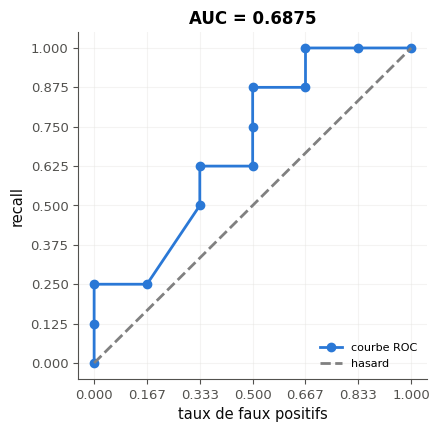

[(0.0, 0.0), (0.0, 0.125), (0.0, 0.25), (0.16666666666666666, 0.25), (0.3333333333333333, 0.5), (0.3333333333333333, 0.625), (0.5, 0.625), (0.5, 0.75), (0.5, 0.875), (0.6666666666666666, 0.875), (0.6666666666666666, 1.0), (0.8333333333333334, 1.0), (1.0, 1.0)]


In [38]:
def roc_points(scores_pos, scores_neg):
    """The vertices (fpr, tpr) of the ROC curve: (0, 0), then one point per distinct score, from the largest to the
    smallest, with the rule "positive if score ≥ threshold"."""
    pos, neg = np.asarray(scores_pos, dtype=float), np.asarray(scores_neg, dtype=float)
    points = [(0.0, 0.0)]
    for threshold in np.unique(np.r_[pos, neg])[::-1]:          # distinct scores, from the largest
        points.append((float(np.mean(neg >= threshold)), float(np.mean(pos >= threshold))))
    return points


def draw_roc(ax, scores_pos, scores_neg):
    """In ax: the ROC curve (segments between the points), the dashed chance diagonal, axis names, the AUC in the
    title."""
    fpr, tpr = zip(*roc_points(scores_pos, scores_neg))
    ax.plot(fpr, tpr, marker="o", linewidth=2, label="courbe ROC")
    ax.plot([0, 1], [0, 1], "--", color="gray", label="hasard")
    ax.set_xticks(np.linspace(0, 1, len(scores_neg) + 1))
    ax.set_yticks(np.linspace(0, 1, len(scores_pos) + 1))
    ax.grid(True, alpha=0.4)
    ax.set(xlabel="taux de faux positifs", ylabel="recall",
           title=f"AUC = {mymath.conditional.auc_by_pairs(scores_pos, scores_neg):.4f}")
    ax.legend(loc="lower right", fontsize=8)


fig, ax = plt.subplots(figsize=(4.5, 4.5))
draw_roc(ax, POS_25, NEG_25)
plt.show()
print(roc_points(POS_25, NEG_25))

**Vérifications automatiques** (sur d'autres scores, avec des ex æquo ; la figure elle-même se juge à l'œil).

In [39]:
with checked("M03.25 vérifications"):
    problems = []
    pos_t, neg_t = [0.9, 0.6, 0.6, 0.3, 0.1], [0.6, 0.4, 0.3, 0.2]       # another example, with ties
    y_t = np.r_[np.ones(len(pos_t)), np.zeros(len(neg_t))]
    fpr_t, tpr_t, _ = roc_curve(y_t, np.r_[pos_t, neg_t], drop_intermediate=False)
    expected = [(float(f), float(t)) for f, t in zip(fpr_t, tpr_t)]
    result = list(roc_points(pos_t, neg_t))
    if (len(result) == 2 and all(np.ndim(part) == 1 and len(part) == len(expected) for part in result)):
        problems.append("roc_points renvoie deux listes (fpr, tpr), comme roc_curve : la docstring demande une liste de "
                        "couples (fpr, tpr), par exemple list(zip(fpr, tpr))")
    else:
        points = [tuple(float(v) for v in point) for point in result]
        if len(points) == len(pos_t) + len(neg_t) + 1:
            problems.append("roc_points : un point par score distinct, pas un par exemple ; des ex æquo passent le "
                            "seuil ensemble et font avancer les deux coordonnées d'un coup")
        elif len(points) != len(expected) or any(abs(a - c) > 1e-9 or abs(b - d) > 1e-9
                                                 for (a, b), (c, d) in zip(points, expected)):
            problems.append("roc_points : un point (0, 0), puis un point par score distinct, du plus grand au plus "
                            "petit, chacun (FPR, recall) avec la règle « score ≥ seuil »")
    fig, ax = plt.subplots(figsize=(4, 4))
    try:
        created = drawn(draw_roc, ax, pos_t, neg_t)
    finally:
        plt.close(fig)                                     # only the checks below are shown here
    if created:
        problems.append("draw_roc ouvre sa propre figure : dessine dans l'axe reçu")
    else:
        lines = [line for line in ax.get_lines() if len(line.get_xdata()) >= 3]
        diagonals = [line for line in ax.get_lines()
                     if np.allclose(np.asarray(line.get_xdata(), dtype=float), np.asarray(line.get_ydata(), dtype=float))
                     and min(line.get_xdata()) <= 0 and max(line.get_xdata()) >= 1]
        curve = None
        for line in lines:
            xy = list(zip(np.asarray(line.get_xdata(), dtype=float), np.asarray(line.get_ydata(), dtype=float)))
            if all(any(abs(x - a) < 1e-9 and abs(y - b) < 1e-9 for x, y in xy) for a, b in expected):
                curve = line
        if curve is None:
            problems.append("la courbe ROC doit passer par tous ses points (FPR, recall) : trace roc_points avec ax.plot")
        else:
            if curve.get_drawstyle() != "default":
                problems.append("relie les points par des segments (ax.plot) : un ex æquo donne un segment oblique, "
                                "que ax.step dessinerait en marche")
            if curve.get_linestyle() in ("None", "none", "", " "):
                problems.append("relie les points par des segments : ax.plot(fpr, tpr), pas des points seuls (le format « o »)")
            xs, ys = np.asarray(curve.get_xdata(), dtype=float), np.asarray(curve.get_ydata(), dtype=float)
            area = float(np.sum((xs[1:] - xs[:-1]) * (ys[1:] + ys[:-1]) / 2))
            if abs(area - roc_auc_score(y_t, np.r_[pos_t, neg_t])) > 1e-9:
                problems.append("l'aire sous la courbe tracée doit être l'AUC : relie dans l'ordre, de (0, 0) à (1, 1), "
                                "les seuls points de roc_points (un par score distinct)")
        if not diagonals:
            problems.append("il manque la diagonale du hasard, de (0, 0) à (1, 1)")
        if not ax.get_xlabel() or not ax.get_ylabel():
            problems.append("nomme les deux axes (taux de faux positifs, recall)")
        if "AUC" not in ax.get_title():
            problems.append("le titre doit donner l'AUC")
    if problems:
        print("❌ Ex M03.25 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M03.25 : une courbe ROC juste, ex æquo compris, avec la diagonale, les axes nommés et l'AUC.")

✅ Ex M03.25 : une courbe ROC juste, ex æquo compris, avec la diagonale, les axes nommés et l'AUC.


💡 Les scores triés : 0,93+, 0,88+, 0,82−, 0,71 (deux + et un −), 0,64+, 0,55−, 0,52+, 0,47+, 0,40−, 0,38+, 0,35−, 0,21−. Au seuil 0,71, deux positifs et un négatif passent ensemble : la courbe va de $(\frac{1}{6} ; \frac{2}{8})$ à $(\frac{2}{6} ; \frac{4}{8})$ en diagonale, et ce segment traverse les $2 \times 1$ cases des paires ex æquo, dont il laisse la moitié dessous. L'AUC vaut $\frac{33}{48} = 0{,}6875$ : 32 paires bien classées et 2 ex æquo (comptés $\frac{1}{2}$), sur 48.

## Partie C · Erreurs classiques, validation et défi

Fiche §1 à §3. Quatre erreurs de conditionnement à trouver, une fonction qui refuse les entrées invalides, puis un tableau à reconstruire.

### Ex M03.26 — Chasse à l'erreur : conditionnelle inversée, marginale oubliée 🐛 ★ ⏱️ 15 min
**Objectif :** repérer dans du code les erreurs classiques du calcul de probabilités conditionnelles, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §2 et §3 · **Parcours :** C

Une plateforme de cours en ligne connaît le niveau de ses inscrits et la probabilité qu'ils terminent un cours selon leur niveau :

```python
p_level = {"débutant": 0.5, "intermédiaire": 0.3, "avancé": 0.2}       # P(niveau)
p_done = {"débutant": 0.2, "intermédiaire": 0.4, "avancé": 0.7}        # P(termine | niveau)
```

Un analyste a écrit six lignes, chacune avec un commentaire qui dit ce qu'elle veut calculer pour un inscrit tiré au hasard. Quatre lignes sont fausses. **Sans exécuter de code**, trouve-les.

```python
p_A = (0.2 + 0.4 + 0.7) / 3          # (A) P(termine)
p_B = 0.7 * 0.2                      # (B) P(avancé et termine)
p_C = 0.7                            # (C) P(avancé | termine)
p_D = 0.5 * 0.8                      # (D) P(débutant | ne termine pas)
p_E = 0.4 + 0.7                      # (E) P(termine | pas débutant)
p_F = 1 - 0.7                        # (F) P(ne termine pas | avancé)
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) pour chacune des six lignes, de (A) à (F), la bonne valeur de ce que dit son commentaire (une liste de 6 nombres, 3 décimales).

Dans ta copie : pour chaque ligne fausse, quelle confusion a été faite ? Une des lignes fausses donne une valeur impossible pour une probabilité : laquelle ?

In [40]:
answer_M03_26a = "ACDE"
p_level = {"débutant": 0.5, "intermédiaire": 0.3, "avancé": 0.2}
p_done = {"débutant": 0.2, "intermédiaire": 0.4, "avancé": 0.7}
done = sum(p_level[k] * p_done[k] for k in p_level)                       # total probability
not_beginner = p_level["intermédiaire"] + p_level["avancé"]
answer_M03_26b = [done,                                                   # (A)
                  p_done["avancé"] * p_level["avancé"],                     # (B) product rule
                  p_done["avancé"] * p_level["avancé"] / done,              # (C) P(avancé ∩ termine) / P(termine)
                  (1 - p_done["débutant"]) * p_level["débutant"] / (1 - done),   # (D)
                  (p_done["intermédiaire"] * p_level["intermédiaire"] + p_done["avancé"] * p_level["avancé"])
                  / not_beginner,                                         # (E)
                  1 - p_done["avancé"]]                                   # (F)
print(answer_M03_26a, [round(v, 4) for v in answer_M03_26b])

ACDE [0.36, 0.14, 0.3889, 0.625, 0.52, 0.3]


In [41]:
wbm.record("M03.26a", "ACDE",
           mistakes={"il manque une ligne fautive : vérifie qu'un taux global tient compte de la taille de chaque groupe": "CDE",
                     "il manque une ligne fautive : vérifie, pour chaque conditionnelle, quel événement est la condition": "ADE",
                     "il manque une ligne fautive : vérifie que chaque conditionnelle divise par la probabilité de sa condition": "ACE",
                     "il manque une ligne fautive : vérifie que chaque résultat est bien une probabilité, calculée sachant la bonne condition": "ACD",
                     "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple": {"ABCDE", "ACDEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : vérifie qu'un taux global tient compte de la taille de chaque groupe": {"BCDE", "CDEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : vérifie, pour chaque conditionnelle, quel événement est la condition": {"ABDE", "ADEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : vérifie que chaque conditionnelle divise par la probabilité de sa condition": {"ABCE", "ACEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : vérifie que chaque résultat est bien une probabilité, calculée sachant la bonne condition": {"ABCD", "ACDF"},
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "C", "D", "E", "AC", "AD", "AE", "CD", "CE", "DE"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"B", "F", "AB", "AF", "BC", "BD", "BE", "BF", "CF", "DF", "EF", "ABC", "ABD", "ABE", "ABF", "ACF", "ADF", "AEF", "BCD", "BCE", "BCF", "BDE", "BDF", "BEF", "CDF", "CEF", "DEF", "ABCF", "ABDF", "ABEF", "BCDF", "BCEF", "BDEF", "ABCDF", "ABCEF", "ABDEF", "BCDEF"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDEF"}})
wbm.record("M03.26b", [0.36, 0.14, 0.14 / 0.36, 0.4 / 0.64, 0.26 / 0.5, 0.3], decimals=3,
           mistakes={"ce sont les valeurs des lignes ; donne les bonnes valeurs de ce que disent les commentaires":
                         [1.3 / 3, 0.14, 0.7, 0.4, 1.1, 0.3]})

WBM_ANSWER {"hash": "9e91803184908863da62b75ea7ea21cee5f4efd914a659a0d1fbf9c4a3dad577", "id": "M03.26a", "kind": "str", "mistakes": {"00fc9100609c404a529501b10b0109297ff5dd65ed35171eede9d27c299859e1": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "01cf5acf71cb02b4b5bfe65fe1cbb4bb0f86a4bddcb4b0d33b3e4cccf19a6cba": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0a9cbd55fd208f29fe86c71908f83108dc7b6478fe216aa7cf7d7ef9b950274b": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0acecc3791cfec39d2e39bb7c6c68b6d262cb9fdd0dc75024f8a01ef61e73727": "une des lignes que tu cites est correcte, et il manque une ligne fautive : vérifie que chaque conditionnelle divise par la probabilité de sa condition", "123022741702b2b38d3ee9905ab3da487e82e74bb6fdfdb54ee9912a98de87c1": "il man

💡 (A) fait la moyenne simple des taux, sans les poids des niveaux : $P(\text{termine}) = 0{,}2 \times 0{,}5 + 0{,}4 \times 0{,}3 + 0{,}7 \times 0{,}2 = 0{,}36$ (probabilités totales, la marginale oubliée). (C) inverse la conditionnelle : 0,7 est $P(\text{termine} \mid \text{avancé})$ ; $P(\text{avancé} \mid \text{termine}) = \frac{0{,}14}{0{,}36} \approx 0{,}389$. (D) calcule la probabilité **jointe** $P(\text{débutant} \cap \text{ne termine pas}) = 0{,}4$ sans la diviser par $P(\text{ne termine pas}) = 0{,}64$ : 0,625. (E) additionne deux probabilités sachant des conditions différentes, et dépasse 1 : $\frac{0{,}12 + 0{,}14}{0{,}5} = 0{,}52$. (B) est la règle du produit et (F) le complément sachant la même condition : justes.

### Ex M03.27 — Une fonction qui refuse un tableau invalide (`ValueError`) 🛠️ ★ ⏱️ 10 min
**Objectif :** écrire une fonction de validation qui refuse les entrées invalides par une `ValueError` au message clair, sans laisser passer le cas piège des NaN.  
**Prérequis :** fiche §1 ; Ex M03.19 · **Parcours :** C

Une fonction qui reçoit des données doit refuser ce qui n'a pas de sens, **tôt** et avec un message clair, plutôt que de renvoyer un résultat faux plus loin. En Python, l'erreur habituelle pour une valeur invalide est la `ValueError`.

Écris `check_joint(table, tol=1e-9)`, qui renvoie le tableau converti en array NumPy de `float` s'il est une loi jointe valide, et lève sinon une `ValueError` dont le message dit **quelle règle** est violée :
- le tableau doit avoir deux dimensions (et au moins une case) ;
- toutes ses cases doivent être positives ou nulles ;
- leur somme doit valoir 1, à `tol` près.

Attention au piège : une case `nan` (*not a number*, une valeur manquante dans un calcul) rend la somme `nan`, et **toute** comparaison avec `nan` est fausse : `abs(nan - 1) > tol` vaut `False`, comme `nan < 0`. `np.isfinite` repère les cases qui ne sont pas des nombres finis.

La vérification essaie huit tableaux, valides ou non.

Dans ta copie : dans quel ordre as-tu écrit les vérifications, et pourquoi l'ordre compte-t-il (que se passe-t-il si l'on additionne les cases d'un tableau vide) ? Ta fonction `_check_joint` de `mymath/conditional.py` résiste-t-elle aux NaN ?

In [42]:
def check_joint(table, tol=1e-9):
    """Return table as a 2-D float array if it is a valid joint law; otherwise raise ValueError with a message that
    says which rule is broken (two dimensions, non-negative finite entries, sum 1 up to tol)."""
    array = np.asarray(table, dtype=float)
    if array.ndim != 2 or array.size == 0:
        raise ValueError(f"a joint law is a non-empty 2-D table, got shape {array.shape}")
    if not np.all(np.isfinite(array)):
        raise ValueError("a joint law has finite entries (no nan, no inf)")
    if np.any(array < 0):
        raise ValueError("a joint law has non-negative entries")
    if abs(array.sum() - 1) > tol:
        raise ValueError(f"the entries of a joint law sum to 1, got {array.sum()}")
    return array


print(check_joint([[0.1, 0.2], [0.3, 0.4]]))

[[0.1 0.2]
 [0.3 0.4]]


In [43]:
with checked("M03.27 vérifications"):
    problems = []
    cases = [("une loi 2 × 2 valide", [[0.1, 0.2], [0.3, 0.4]], True),
             ("une loi d'entiers valide", [[0, 1], [0, 0]], True),
             ("une somme de 1 à 1e-12 près", [[0.1, 0.2], [0.3, 0.4 + 1e-12]], True),
             ("un tableau à une dimension", [0.5, 0.5], False),
             ("une case négative (somme 1)", [[0.6, -0.1], [0.3, 0.2]], False),
             ("une somme de 1,2", [[0.3, 0.3], [0.3, 0.3]], False),
             ("une case NaN", [[float("nan"), 0.5], [0.25, 0.25]], False),
             ("un tableau vide", [[]], False)]
    messages = {}
    for name, table, valid in cases:
        try:
            result = check_joint(table)
        except NotImplementedError:
            raise
        except ValueError as exc:
            if valid:
                problems.append(f"{name} est refusée à tort ({exc})")
            else:
                messages[name] = str(exc)
                if not str(exc).strip():
                    problems.append(f"{name} : la ValueError doit avoir un message qui dit quelle règle est violée")
            continue
        except Exception as exc:  # noqa: BLE001
            problems.append(f"{name} : lève {type(exc).__name__} ; la docstring demande une ValueError")
            continue
        if not valid:
            problems.append(f"{name} est acceptée à tort" + (" (abs(nan − 1) > 1e-9 est False : une comparaison avec "
                                                            "NaN est toujours fausse)" if "NaN" in name else ""))
        elif not (isinstance(result, np.ndarray) and result.dtype == float and result.ndim == 2):
            problems.append(f"{name} : renvoie un array NumPy de float à deux dimensions")
    rules = [messages.get(name) for name in ("un tableau à une dimension", "une case négative (somme 1)",
                                             "une somme de 1,2")]
    if all(rules) and len(set(rules)) < 3:
        problems.append("les trois règles (deux dimensions, cases positives, somme 1) doivent avoir trois messages "
                        "différents : un message doit dire ce qui ne va pas")
    if problems:
        print("❌ Ex M03.27 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M03.27 : les tableaux valides passent, les invalides lèvent une ValueError qui dit pourquoi.")

✅ Ex M03.27 : les tableaux valides passent, les invalides lèvent une ValueError qui dit pourquoi.


💡 L'ordre compte : la forme d'abord (la somme d'un tableau vide vaut 0, et un tableau à une dimension n'a pas de lignes), puis les NaN (sinon `abs(nan - 1) > tol` est faux et le tableau passe), puis le signe, puis la somme. Une case `nan` n'est pas « positive ou nulle » : la référence de `conditional.py` refuse donc une loi qui en contient. Les tests de `mymath` ne vérifient pas ce cas ; essaie la tienne avec `marginal([[np.nan, 0.5], [0.25, 0.25]], 0)`, et corrige-la si elle renvoie un résultat.

### Ex M03.28 — Défi : retrouver un tableau de contingence à partir de quelques probabilités 🏆 ★★★ ⏱️ 25 min
**Objectif :** reconstruire un tableau de contingence à partir de marges et de probabilités conditionnelles, par le calcul ou par une recherche.  
**Prérequis :** fiche §1 à §3 · **Parcours :** C

Une boutique a perdu le tableau de ses 600 visites d'hier, classées selon le canal (appli ou site, en lignes) et le résultat (achat, panier abandonné, ou rien, en colonnes). Il lui reste ces informations, pour une visite tirée au hasard :
1. il y a eu 600 visites ;
2. $P(\text{appli}) = 0{,}4$ ;
3. $P(\text{achat}) = 0{,}5$ ;
4. $P(\text{achat} \mid \text{appli}) = 0{,}625$ ;
5. $P(\text{appli} \mid \text{abandon}) = \frac{1}{6}$ ;
6. $P(\text{rien} \mid \text{site}) = \frac{1}{6}$.

Retrouve le tableau des **effectifs** : `TABLE_28`, une liste de 2 listes de 3 entiers, `[[appli-achat, appli-abandon, appli-rien], [site-achat, site-abandon, site-rien]]`. Deux chemins sont possibles :
- **à la main** : traduis chaque information en une équation sur les cases, et résous-les dans le bon ordre (une case après l'autre) ;
- **par le code** : cherche, parmi les tableaux d'entiers qui ont les bonnes marges, ceux qui vérifient toutes les informations (attention : les comparaisons de fractions se font avec `math.isclose` ou avec `fractions.Fraction`, pas avec `==` sur des flottants).

Puis calcule b) $P(\text{appli} \mid \text{achat ou abandon})$, en fraction irréductible.

La vérification affiche, pour ton tableau, les informations qu'il respecte (✓) ou non (✗), puis vérifie tes réponses.

Dans ta copie : la solution est-elle unique ? Quelles informations suffiraient à la trouver si l'on retirait l'information 6 ? Le canal et le résultat sont-ils indépendants ?

In [44]:
# By hand, one cell at a time: the margins give 240 app visits (2) and 300 purchases (3); then (4) app-purchase =
# 0.625 × 240 = 150, so site-purchase = 150; (6) site-nothing = 360 / 6 = 60, so site-abandoned = 360 − 150 − 60 = 150;
# (5) app-abandoned = a with a / (a + 150) = 1/6, so 6a = a + 150 and a = 30; finally app-nothing = 240 − 150 − 30 = 60.
TABLE_28 = [[150, 30, 60], [150, 150, 60]]
# The same by a search over the tables with the right margins, with exact fractions (each clue prunes the search):
from fractions import Fraction as Fr

found = []
for a in range(241):                                     # app-purchase; site-purchase = 300 − a
    if Fr(a, 240) != Fr(5, 8):                           # clue 4
        continue
    for f in range(361 - (300 - a)):                     # site-nothing
        if Fr(f, 360) != Fr(1, 6):                       # clue 6
            continue
        e = 360 - (300 - a) - f                          # site-abandoned
        for b in range(241 - a):                         # app-abandoned; app-nothing = 240 − a − b
            if b + e > 0 and Fr(b, b + e) == Fr(1, 6):   # clue 5
                found.append([[a, b, 240 - a - b], [300 - a, e, f]])
print("tables found by the search:", found)
answer_M03_28b = str(Fr(150 + 30, 300 + 180))
print("b)", answer_M03_28b)

tables found by the search: [[[150, 30, 60], [150, 150, 60]]]
b) 3/8


In [45]:
wbm.record("M03.28a", [[150, 30, 60], [150, 150, 60]])
wbm.record("M03.28b", "3/8", kind="fraction", simplified=True,
           mistakes={"« sachant achat ou abandon » : divise par le nombre de visites avec un achat ou un abandon":
                         "3/10"})

WBM_ANSWER {"decimals": 0, "element_hashes": ["88fc963e11e80ff8039b710ff9470b4ad119e496daf90ae396936755a6ff476d", "a0b0e743cd32cad2136a8c2f2c4899317c24ca18ef23063c4feeb6c6dbd98d3a", "c736d83444989ff0a8ce77cd0b3e7327082088a251c0c1e4b83f37a6e3266c4e", "8b686f31a02f77e85e667a623425f3c1140dc77463195d0e0e62e599580dc3b8", "34ec2109d51db2f76ba2877e3f3f74f23f714f97886777e16167929a52d288c3", "c43cd2da89a01898503977257f57d742656b5df0d22e03eb531d1dbb017c3cd8"], "hash": "4034f7c60c1c3d8e97cdd35c3590103524d2fd0c8b00a80edeca4f8371174146", "id": "M03.28a", "integer": true, "kind": "array", "shape": [2, 3]}
📝 Ex M03.28a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "1ea6fd2d0547461145b8152b75d5db9f57aa2e13c5419155042d3743199802b9", "id": "M03.28b", "kind": "fraction", "mistakes": {"429bbc6c824d3666f29ed4701bbba0d945b686e26d9c5142ac91bfe4eed20781": "« sachant achat ou abandon » : divise par le nombre de visites avec un achat ou un abandon"}, "sign": 1, "simplified": true}
📝 Ex M03.28b 

💡 L'ordre de résolution : les marges (240 visites sur l'appli, 300 achats), puis l'information 4 donne la case appli-achat ($0{,}625 \times 240 = 150$), donc site-achat (150) ; l'information 6 donne site-rien ($\frac{360}{6} = 60$), donc site-abandon ($360 - 150 - 60 = 150$) ; enfin l'information 5, $\frac{a}{a + 150} = \frac{1}{6}$, donne appli-abandon $a = 30$, et appli-rien $= 60$. La solution est unique : chaque information fixe une case de plus. b) $\frac{150 + 30}{300 + 180} = \frac{3}{8}$. Le canal et le résultat sont dépendants : $P(\text{achat} \mid \text{appli}) = 0{,}625$ mais $P(\text{achat}) = 0{,}5$.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu lire dans un tableau des probabilités jointes, marginales et conditionnelles, décider de l'indépendance, et utiliser les probabilités totales ?
2. Sais-tu écrire chaque mesure d'une matrice de confusion comme une probabilité conditionnelle, et dire comment elle change avec la prévalence et le seuil ?
3. Sais-tu calculer une AUC par les paires, une average precision et un score de Brier, et dire ce que chacun mesure ?

**La suite** : le chapitre 3 de workbookIA (probabilités et métriques de classification), puis M04, la règle de Bayes et la loi Beta.